# Diagnóstico de marca con reseñas de Glassdoor

## Objetivo

Analizar qué valoran y qué critican los empleados de una empresa y su sentimiento hacia la empresa, y comparar
esos temas con empresas consideradas competidoras del mismo sector.
El resultado debe ayudar a RRHH a tener una visión global de la situación, identificar fortalezas e impulsar mejoras.

## 1. Alcance de los datos

Se toma Deutsche Bank como empresa principal y Barclays, Citi y HSBC Holdings
como comparables. Son grandes bancos internacionales del mismo sector, con negocio de banca corporativa y de inversión,
por lo que compiten por perfiles profesionales similares (finanzas, operaciones y tecnología). Además tienen un tamaño de reseñas comparable:
de 5.474 (Deutsche Bank) a 14.609 (Citi) reseñas, muy por encima del mínimo de 300 que pide el enunciado.

In [308]:
from pathlib import Path
import pandas as pd

# Empresas elegidas para el análisis.
empresa = "Deutsche-Bank"
competidoras = ["Barclays", "Citi", "HSBC-Holdings"]
empresas = [empresa] + competidoras

# Localizamos la raíz del proyecto.
carpeta_proyecto = Path.cwd()
if carpeta_proyecto.name == "notebooks":
    carpeta_proyecto = carpeta_proyecto.parent

archivo = carpeta_proyecto/"data"/"glassdoor_reviews_hr.parquet"

# Filtramos al leer el Parquet para cargar solo las empresas elegidas.
df_raw = pd.read_parquet(archivo, filters=[("firm", "in", empresas)])

print(f"Reseñas cargadas: {len(df_raw):,}")
print("\nReseñas por empresa:")
print(df_raw["firm"].value_counts())
print(f"\nColumnas disponibles: {df_raw.columns.tolist()}")

Reseñas cargadas: 36,350

Reseñas por empresa:
firm
Citi             14609
Barclays          9863
HSBC-Holdings     6404
Deutsche-Bank     5474
Name: count, dtype: int64

Columnas disponibles: ['firm', 'date_review', 'current', 'overall_rating', 'recommend', 'pros', 'cons']


Decidimos crear ya dos columnas nuevas que indican la antigüedad del empleado por un lado y la situación del empleado por el otro (a partir de la columna "current") para poder tratar estos aspectos por separado. Si lo hiciéramos más tarde tendríamos que repetir el proceso en cada subconjunto (empresa principal y muestra de NLP).

In [309]:
# La columna `current` contiene la situación del empleado y su antigüedad separada por una coma, las separamos para analizarlas individualmente.
partes_current = df_raw["current"].str.split(",", n=1, expand=True)

# La primera parte siempre indica si el empleado es actual o antiguo.
df_raw["situacion"] = partes_current[0].map({"Current Employee": "Actual","Former Employee": "Antiguo"})

# Si no hay coma, no se declara antigüedad. Conservamos la reseña y marcamos únicamente ese dato como "No indicada".
df_raw["antiguedad"] = (partes_current[1].str.strip().fillna("No indicada"))

# Comprobamos que la transformación no ha eliminado ninguna reseña y que todas las situaciones conocidas se han clasificado.
print("Número de reseñas:", len(df_raw))
print(f"\n{df_raw["situacion"].value_counts(dropna=False)}")
print(f"\n{df_raw["antiguedad"].value_counts(dropna=False)}")

Número de reseñas: 36350

situacion
Actual     23391
Antiguo    12959
Name: count, dtype: int64

antiguedad
No indicada           14399
more than 1 year       6487
more than 3 years      5279
more than 5 years      3338
less than 1 year       3035
more than 10 years     1913
more than 8 years      1899
Name: count, dtype: int64


### Decisión de muestreo

Se conservan todas las reseñas disponibles para hacer el EDA y así tener toda la información posible.
En cambio, para el análisis de sentimiento y de temas se seleccionan aleatoriamente (con semilla fija) hasta 1.000 reseñas por empresa.
Con una semilla fija la selección es reproducible, ninguna empresa domina el modelo conjunto por tener más reseñas y además se reduce el tiempo de cómputo de los modelos.


In [310]:
# Empresa principal.
df = df_raw.loc[df_raw["firm"] == empresa].copy()

# Muestra conjunta: necesaria para comparar sentimiento y topics.
max_reseñas_empresa = 1_000
df_nlp = pd.concat([grupo.sample(n=min(len(grupo), max_reseñas_empresa),random_state=42) for _, grupo in df_raw.groupby("firm")], ignore_index=True)

print("Empresa principal:", len(df))
print("\nMuestra NLP por empresa:")
print(df_nlp["firm"].value_counts())

Empresa principal: 5474

Muestra NLP por empresa:
firm
Barclays         1000
Citi             1000
Deutsche-Bank    1000
HSBC-Holdings    1000
Name: count, dtype: int64


## 2. Primer análisis de los datos.

In [311]:
# Vista general de las primeras filas.
df.head()

,firm,date_review,current,overall_rating,recommend,pros,cons,situacion,antiguedad
24472,Deutsche-Bank,2018-07-27,"Current Employee, more than 1 year",5.0,v,Opportunities for professional growth,Discriminations coming from the co-workers,Actual,more than 1 year
24473,Deutsche-Bank,2018-07-27,Current Employee,4.0,v,The logo is very simple,no organization is always perfect,Actual,No indicada
24474,Deutsche-Bank,2018-07-27,Former Employee,4.0,v,"Great Office, Great People, Flexible hours",A steep curve for promotions,Antiguo,No indicada
24475,Deutsche-Bank,2018-07-28,Current Employee,4.0,o,Good people and decent pay,sometimes the hours are long,Actual,No indicada
24476,Deutsche-Bank,2018-07-28,Former Employee,2.0,x,Pay good salary because they have to in order ...,"Where to begin? Insanely inefficient systems, ...",Antiguo,No indicada


In [312]:
# Exploramos los nulos y el tipo de dato de cada columna. 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5474 entries, 24472 to 29945
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   firm            5474 non-null   str    
 1   date_review     5474 non-null   object 
 2   current         5474 non-null   str    
 3   overall_rating  5474 non-null   float64
 4   recommend       5474 non-null   str    
 5   pros            5474 non-null   str    
 6   cons            5474 non-null   str    
 7   situacion       5474 non-null   str    
 8   antiguedad      5474 non-null   str    
dtypes: float64(1), object(1), str(7)
memory usage: 1.4+ MB


In [313]:
df.describe(include="all")

,firm,date_review,current,overall_rating,recommend,pros,cons,situacion,antiguedad
count,5474,5474,5474,5474.000000,5474,5474,5474,5474,5474
unique,1,1559,14,NaN,3,5411,5427,2,7
top,Deutsche-Bank,2021-01-13,Current Employee,NaN,v,Work life balance is good,None that I can think of,Actual,No indicada
freq,5474,15,1412,NaN,2376,12,15,3448,2130
mean,NaN,NaN,NaN,3.728900,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,1.100279,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,NaN


In [314]:
# Exploramos los 14 valores distintos en la columna "current"
df["current"].value_counts(dropna=False)

current
Current Employee                        1412
Former Employee                          718
Current Employee, more than 1 year       563
Current Employee, more than 3 years      540
Former Employee, more than 1 year        379
Former Employee, more than 3 years       368
Current Employee, more than 5 years      336
Current Employee, less than 1 year       272
Former Employee, more than 5 years       212
Current Employee, more than 8 years      171
Current Employee, more than 10 years     154
Former Employee, less than 1 year        150
Former Employee, more than 8 years       105
Former Employee, more than 10 years       94
Name: count, dtype: int64

In [315]:
df["overall_rating"].value_counts()

overall_rating
4.0    2051
5.0    1471
3.0    1247
2.0     407
1.0     298
Name: count, dtype: int64

In [316]:
print(df["situacion"].value_counts(dropna=False))
display(df[["current", "situacion", "antiguedad"]].drop_duplicates().sort_values("current"))

situacion
Actual     3448
Antiguo    2026
Name: count, dtype: int64


,current,situacion,antiguedad
24473,Current Employee,Actual,No indicada
24536,"Current Employee, less than 1 year",Actual,less than 1 year
24472,"Current Employee, more than 1 year",Actual,more than 1 year
24505,"Current Employee, more than 10 years",Actual,more than 10 years
24495,"Current Employee, more than 3 years",Actual,more than 3 years
24490,"Current Employee, more than 5 years",Actual,more than 5 years
24481,"Current Employee, more than 8 years",Actual,more than 8 years
24474,Former Employee,Antiguo,No indicada
24549,"Former Employee, less than 1 year",Antiguo,less than 1 year
24483,"Former Employee, more than 1 year",Antiguo,more than 1 year


## Análisis Exploratorio de Datos 
Primero analizaremos rating y recomendaciones, sus diferencias entre empleados actuales y antiguos, la comparación con los peers y la evolución temporal. 
Por último, estudiaremos los textos de `pros` y `cons` para explorar los temas que pueden estar detrás de esas valoraciones.

Debemos tener en cuenta que las reseñas son opiniones voluntariasy no describen necesariamente la opinión de toda la plantilla. 

### ¿Cómo valoran los empleados a Deutsche Bank?

In [317]:
# Claculamos su overall rating.
print("Puntuación global:")
display(df["overall_rating"].describe().round(2))

Puntuación global:


count    5474.00
mean        3.73
std         1.10
min         1.00
25%         3.00
50%         4.00
75%         5.00
max         5.00
Name: overall_rating, dtype: float64

v = Recomendaría la empresa.    x = No la recomendaría   o = No opino

In [318]:
# Traducimos los códigos a respuestas comprensibles.
etiquetas_recommend = {
    "v": "Sí recomienda",
    "x": "No recomienda",
    "o": "Sin opinión"}


# Convertimos el restultado en una tabla de 2 columnas (etiquetas y recuento de reseñas)
tabla_recomendacion = (df["recommend"].map(etiquetas_recommend).value_counts().reset_index(name="reseñas"))

# Añadimos una columna con el porcentaje del recuento de reseñas
tabla_recomendacion["porcentaje"] = (tabla_recomendacion["reseñas"] / len(df) * 100).round(1)

display(tabla_recomendacion)

,recommend,reseñas,porcentaje
0,Sí recomienda,2376,43.4
1,Sin opinión,2121,38.7
2,No recomienda,977,17.8


Deutsche Bank tiene un rating medio de 3,73/5: el 43,4 % recomendaría la empresa, el 17,8 % no la recomendaría y el 38,7 % no expresa una opinión al respecto. 

### ¿Cambia la valoración del empleado según su situación?

Comparamos el overall rating de los empleados actuales y antiguos de Deutsche Bank. Mostramos también el número de reseñas de cada grupo para interpretar las medias en su contexto.

In [319]:
rating_por_situacion = (df.groupby("situacion")["overall_rating"].agg(reseñas="count",media_rating="mean",mediana_rating="median").round(2))

display(rating_por_situacion)

,reseñas,media_rating,mediana_rating
situacion,,,
Actual,3448,3.87,4.0
Antiguo,2026,3.49,4.0


Los empleados antiguos otorgan una puntuación media 0,38 puntos inferior a la de los empleados actuales (3,49 frente a 3,87 sobre 5). Esta diferencia justifica analizar por separado sus críticas.

In [320]:
# Cada fila suma 100 %: comparamos las respuestas dentro de cada grupo.
recomendacion_por_situacion = pd.crosstab(df["situacion"],df["recommend"].map(etiquetas_recommend),normalize="index") * 100

display(recomendacion_por_situacion.round(1))

recommend,No recomienda,Sin opinión,Sí recomienda
situacion,,,
Actual,14.4,38.5,47.2
Antiguo,23.8,39.2,37.0


Los antiguos empleados recomiendan menos la empresa que los actuales (10,2 puntos porcentuales menos), algo habitual por el sesgo de selección: quien se va suele hacerlo con peor opinión que quien se queda. Por eso la comparación útil entre ambos grupos será la de temas y no la de puntuaciones. Además el porcentaje de empleados antiguos que no la recomienda es mucho más alto (23,8%) que el porcentaje de empleados actuales (14,4%).

### ¿Cómo se sitúa Deutsche Bank frente a sus competidores?

In [321]:
# Resumen por empresa con todas las reseñas: volumen, rating medio, % que recomienda y reparto entre actuales y antiguos.
resumen_empresas = df_raw.groupby("firm").agg(
    reseñas=("overall_rating", "size"),
    rating_medio=("overall_rating", "mean"),
    recomienda_pct=("recommend", lambda x: (x == "v").mean() * 100),
    actuales_pct=("situacion", lambda x: (x == "Actual").mean() * 100))

resumen_empresas["antiguos_pct"] = 100 - resumen_empresas["actuales_pct"]

display(resumen_empresas.round(2))

,reseñas,rating_medio,recomienda_pct,actuales_pct,antiguos_pct
firm,,,,,
Barclays,9863,3.89,47.98,65.94,34.06
Citi,14609,3.78,45.74,66.50,33.50
Deutsche-Bank,5474,3.73,43.41,62.99,37.01
HSBC-Holdings,6404,3.71,46.96,58.15,41.85


Deutsche Bank no es el banco peor valorado (3,73 de rating medio, por encima de HSBC con 3,71), pero sí el que menos reseñas con recomendación tiene (43,4 %, frente a un 45,7-48,0 % en los demás). Entre los cuatro bancos las diferencias de rating son pequeñas (de 3,71 a 3,89), así que ninguno se separa mucho del resto. El 37,0 % de las reseñas de Deutsche Bank son de antiguos empleados, solo por detrás de HSBC (41,9 %).

**Conclusión accionable:** Conviene vigilar el porcentaje de recomendación además del rating, porque es donde Deutsche Bank sale peor parado. Y como una de cada tres reseñas es de alguien que ya se ha ido, tiene sentido estudiar sus motivos de salida más adelante.

In [322]:
# df_raw conserva las reseñas completas de los cuatro bancos.
comparacion_situacion = (df_raw.groupby(["firm", "situacion"])["overall_rating"].mean().unstack())

# Calculamos la diferencia entre lo que puntuan los empleados actuales y los antiguos.
comparacion_situacion["diferencia"] = (comparacion_situacion["Actual"]- comparacion_situacion["Antiguo"])

display(comparacion_situacion.round(2))

situacion,Actual,Antiguo,diferencia
firm,,,
Barclays,4.02,3.64,0.38
Citi,3.91,3.54,0.37
Deutsche-Bank,3.87,3.49,0.39
HSBC-Holdings,3.79,3.60,0.19


En los cuatro bancos analizados, las reseñas de empleados actuales tienen una puntuación media superior a las de antiguos empleados. 

La diferencia de Deutsche Bank (0,39 puntos) es similar a la de Barclays (0,38) y Citi (0,37), por lo que la brecha no parece exclusiva de la empresa. 
Es importante que nos fijemps en que Deutsche Bank presenta la media más baja entre antiguos empleados (3,49), algo que merece seguir analizando.

In [323]:
# Porcentajes de respuesta dentro de cada banco.
recomendacion_por_banco = pd.crosstab(df_raw["firm"],df_raw["recommend"].map(etiquetas_recommend),normalize="index") * 100

display(recomendacion_por_banco.round(1))

recommend,No recomienda,Sin opinión,Sí recomienda
firm,,,
Barclays,13.7,38.3,48.0
Citi,16.0,38.3,45.7
Deutsche-Bank,17.8,38.7,43.4
HSBC-Holdings,18.3,34.8,47.0


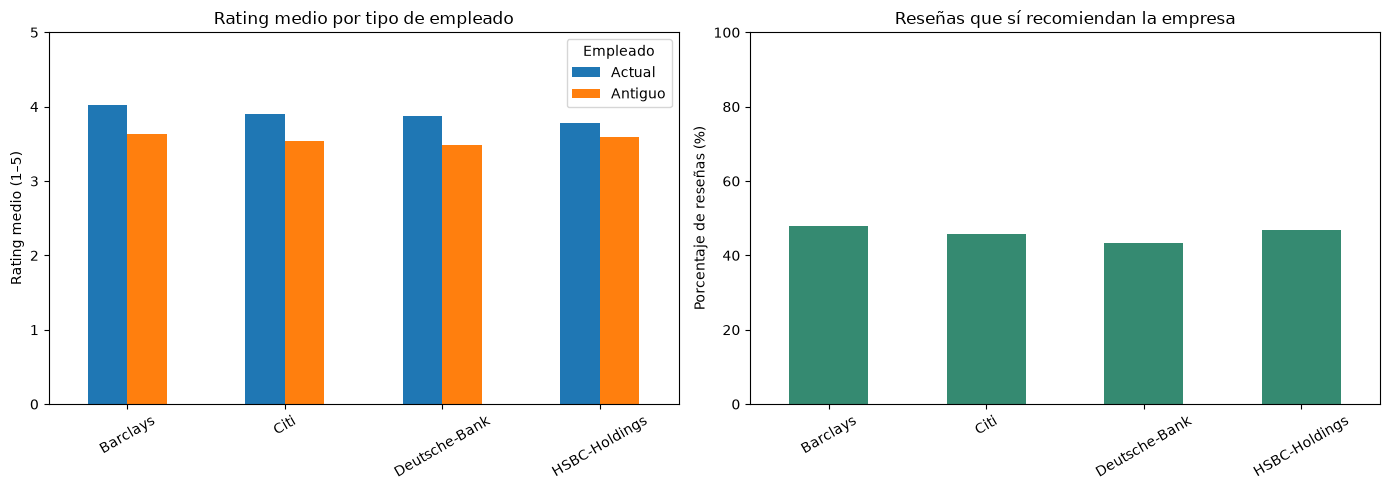

In [324]:
# Creamos un gráfico con 2 paneles: uno para el rating de actuales y antiguos y otro para el % que sí recomienda cada banco.
import matplotlib.pyplot as plt

fig, (ax_rating, ax_recommend) = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: rating medio según la situación del empleado.
comparacion_situacion[["Actual", "Antiguo"]].plot(kind="bar",ax=ax_rating)
ax_rating.set_title("Rating medio por tipo de empleado")
ax_rating.set_xlabel("")
ax_rating.set_ylabel("Rating medio (1–5)")
ax_rating.set_ylim(0, 5)
ax_rating.legend(title="Empleado")
ax_rating.tick_params(axis="x", rotation=30)

# Panel 2: porcentaje que sí recomendaría cada banco.
recomendacion_por_banco["Sí recomienda"].plot(kind="bar",ax=ax_recommend, color="#358A71")
ax_recommend.set_title("Reseñas que sí recomiendan la empresa")
ax_recommend.set_xlabel("")
ax_recommend.set_ylabel("Porcentaje de reseñas (%)")
ax_recommend.set_ylim(0, 100)
ax_recommend.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

En general, Los empleados de todas las empresas recomiendan su empresa entre un 43% y un 48%, es decir, ningún banco destaca claramente en recomendación. Recordemos que las valoraciones son voluntarias. 

Deutsche Bank tiene el menor porcentaje de «Sí recomienda» entre los cuatro bancos analizados, con un 43,4 %, una diferencia de 4,6 puntos porcentuales contra la empresa más recomendada (Barclays).
Además, Deutsche Bank es una de las empresas con mayor porcentaje de no recomendaciones (en segunda posición con un 17,8%), detrás de HSBC-Holdings.

La categoría «Sin opinión» representa entre el 34,8% y el 38,7% según el banco, por lo que debe mantenerse visible al interpretar estos porcentajes.

### ¿Cómo evoluciona la valoración con el tiempo?

Calculamos el rating medio anual de Deutsche Bank junto con el número de reseñas de cada año. El volumen permite valorar cuánto respaldo tiene cada media. Los años 2018 y 2023 pueden estar incompletos por los límites temporales del dataset.

In [325]:
# Extraemos el año de la fecha de publicación de cada reseña.
df["anio"] = pd.to_datetime(df["date_review"]).dt.year

# Creamos una tabla con el recuento de las reseñas agrupadas por año y su rating medio.
evolucion_rating = (df.groupby("anio").agg(reseñas=("overall_rating", "count"),rating_medio=("overall_rating", "mean")))

display(evolucion_rating.round(2))

,reseñas,rating_medio
anio,,
2018,303,3.40
2019,749,3.40
2020,866,3.74
2021,1639,3.80
2022,1551,3.84
2023,366,3.87


El rating medio de las reseñas de Deutsche Bank pasa de 3,40 en 2019 a 3,84 en 2022. En 2023 alcanza 3,87, aunque ese dato solo cubre hasta julio.
El volumen de reseñas también cambia entre años, por lo que mostramos siempre el número de observaciones junto a la media. Encontramos una tendencia ascendente en el rating medio.

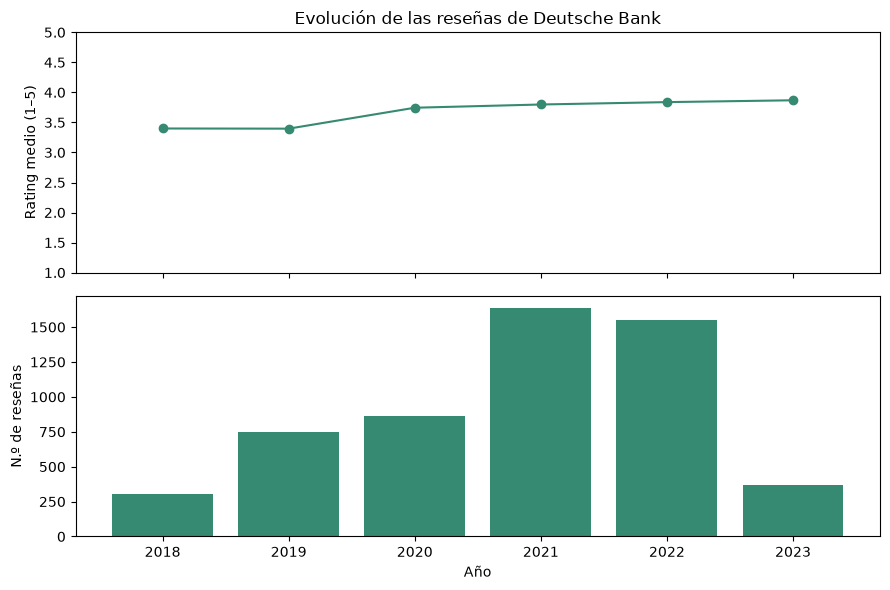

In [326]:
# Creamos un gráfico para mostrar dicha tendencia.
fig, (ax_rating, ax_volumen) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax_rating.plot(evolucion_rating.index,evolucion_rating["rating_medio"],marker="o", color="#358A71")
ax_rating.set_ylabel("Rating medio (1–5)")
ax_rating.set_ylim(1, 5)
ax_rating.set_title("Evolución de las reseñas de Deutsche Bank")

# Como hay cambios significativos en la cantidad de reseñas a lo alrgo de los años es mejor que expongamos también este cambio con otro gráfico. 
ax_volumen.bar(evolucion_rating.index,evolucion_rating["reseñas"], color="#358A71")
ax_volumen.set_ylabel("N.º de reseñas")
ax_volumen.set_xlabel("Año")

plt.tight_layout()
plt.show()

El rating medio de las reseñas de Deutsche Bank se mantiene en 3,40 en 2018 y 2019, tenemos una subida considerable a 3,74 en 2020 y continúa aumentando hasta 3,84 en 2022, de forma más moderada. 
En 2023 alcanza 3,87, aunque este último dato solo incluye reseñas hasta julio.

El volumen de reseñas también cambia: 2021 y 2022 concentran más de 1.500 reseñas cada uno, mientras que 2018 y 2023 son años parciales y
tienen menos observaciones. Por ello, la subida entre 2019 y 2022 es más útil para describir la evolución que una comparación directa entre 2018 y 2023.

El gráfico muestra una mejora en las puntuaciones publicadas, pero no sabemos todavía qué la causó y tampoco refleja la experiencia de toda la plantilla. 

### ¿Cómo evoluciona Deutsche Bank frente a sus competidores a lo largo del tiempo?

In [327]:
# Calculamos año y rating medio para los cuatro bancos.
df_raw["anio"] = pd.to_datetime(df_raw["date_review"]).dt.year

evolucion_bancos = (df_raw.groupby(["anio", "firm"]).agg(reseñas=("overall_rating", "count"),rating_medio=("overall_rating", "mean")).reset_index())

# Años en filas y bancos en columnas para comparar sus medias.
tabla_evolucion = evolucion_bancos.pivot(index="anio",columns="firm",values="rating_medio")

display(tabla_evolucion.round(2))


tabla_volumen = evolucion_bancos.pivot(index="anio",columns="firm",values="reseñas")

display(tabla_volumen.fillna(0).astype(int))

firm,Barclays,Citi,Deutsche-Bank,HSBC-Holdings
anio,,,,
2018,3.87,3.50,3.40,3.71
2019,3.75,3.54,3.40,3.66
2020,3.89,3.84,3.74,3.74
2021,3.89,3.83,3.80,3.71
2022,3.95,3.83,3.84,NaN
2023,3.93,3.79,3.87,NaN


firm,Barclays,Citi,Deutsche-Bank,HSBC-Holdings
anio,,,,
2018,420,630,303,570
2019,1359,1654,749,1717
2020,1593,2030,866,2091
2021,3254,4739,1639,2026
2022,2706,4655,1551,0
2023,531,901,366,0


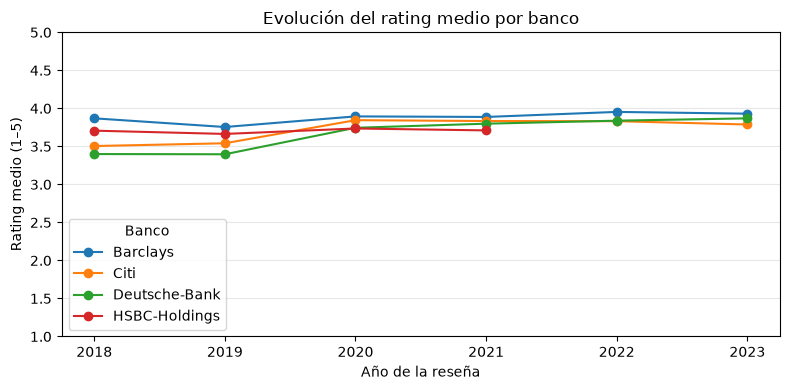

In [328]:
# Comparamos la evolución del rating medio de los cuatro bancos.
ax = tabla_evolucion.plot(kind="line",marker="o",figsize=(8, 4))

ax.set_title("Evolución del rating medio por banco")
ax.set_xlabel("Año de la reseña")
ax.set_ylabel("Rating medio (1–5)")
ax.set_ylim(1, 5)
ax.set_xticks(tabla_evolucion.index)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Banco")

plt.tight_layout()
plt.show()

La subida entre 2019 y 2020 también aparece en los otros tres bancos, por lo que no parece un cambio exclusivo de Deutsche Bank. En 2022, Deutsche Bank (3,84) continúa por debajo de Barclays (3,95), mientras que Citi registra 3,83.

La cantidad de reseñas dan contexto a estas medias: Deutsche Bank tiene entre 749 y 1.639 reseñas anuales de 2019 a 2022. En cambio, 2018 y 2023 son años parciales. 
HSBC Holdings no tiene reseñas en el dataset para 2022 y 2023, por lo que no se puede incluir en la comparación de esos años.

En el gráfico observamos como Deutsche Bank empezó siendo el banco con un rating medio más bajo pero poco a poco a ido aumentando y aunque no es el banco con mayor puntuación si es un banco que ha ido mejorando su rating medio durante los años de manera progresiva, más que sus competidores. 

### ¿Qué aspectos positivos y negativos mencionan los empleados de Deutsche Bank?

In [329]:
# Leemos una pequeña muestra de comentarios de Deutsche Bank para conocer el contenido.
muestra_textos = df[["pros", "cons"]]

display(muestra_textos.head())

,pros,cons
24472,Opportunities for professional growth,Discriminations coming from the co-workers
24473,The logo is very simple,no organization is always perfect
24474,"Great Office, Great People, Flexible hours",A steep curve for promotions
24475,Good people and decent pay,sometimes the hours are long
24476,Pay good salary because they have to in order ...,"Where to begin? Insanely inefficient systems, ..."


In [330]:
# Comprobamos que no haya celdas vacías o que solo contengan espacios.
for columna in ["pros", "cons"]:
    textos = df[columna].str.strip()

    print(f"{columna}:")
    print(f"  Con contenido: {textos.ne('').sum()}")
    print(f"  Vacíos o ausentes: {textos.eq('').sum()}")

pros:
  Con contenido: 5474
  Vacíos o ausentes: 0
cons:
  Con contenido: 5474
  Vacíos o ausentes: 0


In [331]:
# Medimos la longitud de los comentarios en número de palabras para saber si trabajamos con comentarios muy extensos que deberemos revisar o con comentarios cortos con poca información.
longitud_textos = pd.DataFrame({
    "pros": df["pros"].str.split().str.len(),
    "cons": df["cons"].str.split().str.len()})

display(longitud_textos.describe().round(1))

,pros,cons
count,5474.0,5474.0
mean,9.4,12.9
std,8.6,23.5
min,4.0,4.0
25%,6.0,6.0
50%,7.0,7.0
75%,10.0,11.0
max,147.0,571.0


In [332]:
# Revisamos el comentario negativo más largo antes de tomar decisiones.
texto_mas_largo = longitud_textos["cons"].idxmax()

print("Número de palabras:", longitud_textos.loc[texto_mas_largo, "cons"])
print(df.loc[texto_mas_largo, "cons"])

Número de palabras: 571
1) Is there ever a month that goes by in which Deutsche Bank isn't in the news for money laundering? It's demoralising working for an organisation that has a nefarious history and continues to be involved in dodgy activities. With the hundreds of millions spent on KYC processes at DB, it's incredible that such crimes continued to still occur very frequently. 

2) The resource planning that I witnessed was at times absolutely absurd. It got to the point where some teams were incredibly stretched working on key deliverables with tight deadlines and with a small team. And yet, DB hired external consultants on several ocassions who would be paid extortinate sums of money to come up with 'digital transformation' ideas that would be executed by DB engineers. So, the company is paying at least twice. That inconsistent approach to resourcing seemed to happen frequently. 

3) Some colleagues, especially around the VP level, are medicore and there's a layer of fat who enj

Los comentarios suelen son breves (con una mediana de 7 palabras), aunque existen reseñas extensas que pueden tratar sobre varios temas distintos. 

Hemos comprobado que el texto más largo no se trata de un error sino de un comentario que menciona varias críticas distintas e incluso las numera. 
Esto nos indica que una reseña puede hablar de varios temas. Si más adelante el modelo le asigna un único tema, perderá parte de ese detalle. Y al analizar el sentimiento, tendremos que comprobar el límite de texto que admite el modelo, porque un comentario de 571 palabras podría truncarse.


## Análisis de texto (NLP)

In [333]:
# Verificamos la muestra que utilizaremos en los modelos de NLP.
display(df_nlp["firm"].value_counts())


firm
Barclays         1000
Citi             1000
Deutsche-Bank    1000
HSBC-Holdings    1000
Name: count, dtype: int64

In [334]:
# Hacemos una comprobación inciial de calidad para ver si las predicciones tienen sentido con comentarios reales de Glassdoor.
from transformers import pipeline

# Cargamos un modelo de clasificación de sentimiento en inglés.
analizador_sentimiento = pipeline(task="sentiment-analysis", model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")

# Elegimos una reseña al azar (la primera en este caso) y analizamos su pro y su con.
reseña = df_nlp.iloc[0]

print("Banco:", reseña["firm"])
print("\nPRO:", reseña["pros"])
print("Predicción:", analizador_sentimiento(reseña["pros"]))
print("\nCON:", reseña["cons"])
print("Predicción:", analizador_sentimiento(reseña["cons"]))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Banco: Barclays

PRO: Good work life balance Had a great management Learned lots
Predicción: [{'label': 'POSITIVE', 'score': 0.9996131062507629}]

CON: I would say.. May be the compensation
Predicción: [{'label': 'NEGATIVE', 'score': 0.9907791614532471}]


Ahora que hemos comprobado que el código del modelo funciona, pasamos a hacer una comprobación para evaluar si el modelo nos sirve para este proyecto.

In [335]:
# Buscamos cinco reseñas al azar para examinar distintos tipos de texto.
ejemplos_sentimiento = df_nlp[["firm", "pros", "cons"]].sample(n=5, random_state=17)

display(ejemplos_sentimiento)

,firm,pros,cons
3199,HSBC-Holdings,"Good company, good development prospects if yo...",Don’t value loyal staff and don’t reward their...
3099,HSBC-Holdings,Clear company structure and incentive reward,Long working hours every day
2883,Deutsche-Bank,"High quality staff, nice offices, very profess...",Constant cost cutting and limited scope for mo...
179,Barclays,Amazing people and still great flexibility,Underpay relative to the street
360,Barclays,Work life balance is better,"Moderately challenging, can be better"


In [336]:
# Vemos los textos de las cinco reseñas seleccionadas.
for indice, fila in ejemplos_sentimiento.iterrows():
    print(f"\nReseña {indice} — {fila['firm']}")
    print("PRO:", fila["pros"])
    print("CON:", fila["cons"])


Reseña 3199 — HSBC-Holdings
PRO: Good company, good development prospects if you work hard, good locations globally if opportunities arose to move internally to a new country
CON: Don’t value loyal staff and don’t reward their top talent in line with expectations

Reseña 3099 — HSBC-Holdings
PRO: Clear company structure and incentive reward
CON: Long working hours every day

Reseña 2883 — Deutsche-Bank
PRO: High quality staff, nice offices, very professional
CON: Constant cost cutting and limited scope for mobility or advancement

Reseña 179 — Barclays
PRO: Amazing people and still great flexibility
CON: Underpay relative to the street

Reseña 360 — Barclays
PRO: Work life balance is better
CON: Moderately challenging, can be better


In [337]:
# Analizamos primero todos los pros y después todos los cons.
for columna in ["pros", "cons"]:
    resultados = analizador_sentimiento(ejemplos_sentimiento[columna].tolist(), truncation=True) #truncamos el comentario por si es muy largo.
    ejemplos_sentimiento[f"sentimiento_{columna}"] = [resultado["label"] for resultado in resultados]

display(ejemplos_sentimiento[["firm", "pros", "sentimiento_pros", "cons", "sentimiento_cons"]])

,firm,pros,sentimiento_pros,cons,sentimiento_cons
3199,HSBC-Holdings,"Good company, good development prospects if yo...",POSITIVE,Don’t value loyal staff and don’t reward their...,NEGATIVE
3099,HSBC-Holdings,Clear company structure and incentive reward,POSITIVE,Long working hours every day,POSITIVE
2883,Deutsche-Bank,"High quality staff, nice offices, very profess...",POSITIVE,Constant cost cutting and limited scope for mo...,NEGATIVE
179,Barclays,Amazing people and still great flexibility,POSITIVE,Underpay relative to the street,NEGATIVE
360,Barclays,Work life balance is better,POSITIVE,"Moderately challenging, can be better",POSITIVE


En la muestra de 5 reseñas (10 comentarios entre pros y cons) el modelo ha fallado en 2 comentarios. Esto nos indica que las rpedicciones necesitan una revisión cualitativa y no se deben interpretar como medidas directas de satisfacción.

In [338]:
# Revisamos la confianza del modelo en los dos casos de error.
for indice in [3099, 360]:
    texto = ejemplos_sentimiento.loc[indice, "cons"]
    resultado = analizador_sentimiento(texto)[0]

    print(f"\nReseña {indice}: {texto}")
    print(f"Predicción: {resultado['label']}")
    print(f"Score: {resultado['score']:.3f}")


Reseña 3099: Long working hours every day
Predicción: POSITIVE
Score: 0.969

Reseña 360: Moderately challenging, can be better
Predicción: POSITIVE
Score: 0.993


Este modelo sirve para demostrar el procedimiento, pero ha demostrado errores con un score de seguridad muy alto, no usaremos sus porcentajes como resutlado final sin compara antes alguna alternativa más.

Para ello seleccionamos SiEBERT: su ficha indica que clasifica sentimiento positivo/negativo en inglés y que se ajustó y evaluó con 15 conjuntos de textos de distintos tipos, entre ellos reseñas.

In [339]:
# Cargamos el segundo modelo candidato para comparar sus predicciones.
analizador_siebert = pipeline(task="sentiment-analysis", model="siebert/sentiment-roberta-large-english")

# Repetimos exactamente los dos casos que dieron problemas.
for indice in [3099, 360]:
    texto = ejemplos_sentimiento.loc[indice, "cons"]
    resultado = analizador_siebert(texto, truncation=True)[0]
    print(f"\nReseña {indice}: {texto}")
    print(f"Predicción SiEBERT: {resultado['label']}")
    print(f"Score: {resultado['score']:.3f}")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]


Reseña 3099: Long working hours every day
Predicción SiEBERT: POSITIVE
Score: 0.998

Reseña 360: Moderately challenging, can be better
Predicción SiEBERT: NEGATIVE
Score: 0.996


Como los resultados del análisis de sentimiento no han devuelto un resultado del todo satisfactorio, sería conveniente continuar con la exploración de las reseñas y clasificarlas primero manualmente para encontrar los errores reales.

In [340]:
# Para la primera revisión, elegimos reseñas cuyos dos comentarios sean breves.
candidatas = df_nlp[df_nlp["pros"].str.len().between(20, 180) & df_nlp["cons"].str.len().between(20, 180)]

muestra_breve = (candidatas.groupby("firm", group_keys=False)
    .sample(n=1, random_state=42)
    [["firm", "pros", "cons"]])

for indice, fila in muestra_breve.iterrows():
    print(f"\nReseña {indice} — {fila['firm']}")
    print("PRO:", fila["pros"])
    print("CON:", fila["cons"])


Reseña 956 — Barclays
PRO: Barclays is a company where one can really grow and develop their selves in the field. Barclays give the opportunities to work in a happy environment.
CON: No such problems are there according to me. Its always a pleasure to work with Barclays

Reseña 1940 — Citi
PRO: Big push for diversity and inclusion in the workspace
CON: Very bureaucratic, lots of times very stressful with long hours

Reseña 2142 — Deutsche-Bank
PRO: Best place to start a career
CON: Nothing as such with my experience

Reseña 3431 — HSBC-Holdings
PRO: working for a big company.
CON: systems are outdated, processes are cumbersome. you have to complete your 1-1 documents and continued training in your own time as they don't give you any.


Podemos observar como hay comentarios neutros en columnas de pros (como en la reseña de HSBC) y comentarios positivos en la columna de cons (como en la reseña de Barclays).

In [341]:
# Primero vamos a probar con el primer modelo utilizado (DistilBERT).
for indice, fila in muestra_breve.iterrows():
    print(f"\nReseña {indice} — {fila['firm']}")

    for columna in ["pros", "cons"]:
        prediccion = analizador_sentimiento(fila[columna])[0]
        print(f"{columna.upper()}: {prediccion['label']} (score: {prediccion['score']:.3f})")


Reseña 956 — Barclays
PROS: POSITIVE (score: 1.000)
CONS: POSITIVE (score: 0.999)

Reseña 1940 — Citi
PROS: POSITIVE (score: 0.995)
CONS: NEGATIVE (score: 0.951)

Reseña 2142 — Deutsche-Bank
PROS: POSITIVE (score: 0.999)
CONS: NEGATIVE (score: 0.981)

Reseña 3431 — HSBC-Holdings
PROS: POSITIVE (score: 0.994)
CONS: NEGATIVE (score: 1.000)


Al parecer hay un solo caso en el que nuestra clasificación y la del modelo no coincide; la reseña cons de Deutsche Bank. El modelo parece interpretar la palabra "nothing" como algo negativo.

Antes de sacar conclusiones vamos a probar SiEBERT sobre estas mismas reseñas para ver si coincide más con nuestra clasificación manual. 

In [342]:
for indice, fila in muestra_breve.iterrows():
    print(f"\nReseña {indice} — {fila['firm']}")

    for columna in ["pros", "cons"]:
        prediccion = analizador_siebert(fila[columna])[0]
        print(f"{columna.upper()}: {prediccion['label']} (score: {prediccion['score']:.3f})")


Reseña 956 — Barclays
PROS: POSITIVE (score: 0.999)
CONS: POSITIVE (score: 0.999)

Reseña 1940 — Citi
PROS: POSITIVE (score: 0.999)
CONS: NEGATIVE (score: 0.997)

Reseña 2142 — Deutsche-Bank
PROS: POSITIVE (score: 0.999)
CONS: NEGATIVE (score: 0.998)

Reseña 3431 — HSBC-Holdings
PROS: NEGATIVE (score: 0.991)
CONS: NEGATIVE (score: 0.999)


En este caso vemos como no solamente no ha habido una mejora en las coincidencias con nuestra clasificación manual sino que además se añade una incoherencia más en la reseña de cons de HSBC. 

Por lo tanto, DistilBERT ha ofrecido resultados más acordes con la lectura humana que hicimos, aunque ambos fallaron en una de las reseñas observadas. Así que se conserva DistilBERT como modelo de referencia exploratorio teniendo en cuenta sus limitaciones.

In [343]:
# Conservamos la empresa y los textos originales junto a las predicciones.
df_sentimiento = df_nlp[["firm", "pros", "cons"]].copy()

# DistilBERT analiza cada columna por separado.
predicciones_pros = analizador_sentimiento(df_sentimiento["pros"].tolist(), truncation=True, batch_size=16)

predicciones_cons = analizador_sentimiento(df_sentimiento["cons"].tolist(), truncation=True, batch_size=16)

# Guardamos las etiquetas; en esta fase no necesitamos el score.
df_sentimiento["sentimiento_pros"] = [prediccion["label"] for prediccion in predicciones_pros]
df_sentimiento["sentimiento_cons"] = [prediccion["label"] for prediccion in predicciones_cons]

display(df_sentimiento[["firm", "sentimiento_pros", "sentimiento_cons"]])

,firm,sentimiento_pros,sentimiento_cons
0,Barclays,POSITIVE,NEGATIVE
1,Barclays,POSITIVE,NEGATIVE
2,Barclays,POSITIVE,POSITIVE
3,Barclays,POSITIVE,NEGATIVE
4,Barclays,POSITIVE,NEGATIVE
...,...,...,...
3995,HSBC-Holdings,POSITIVE,NEGATIVE
3996,HSBC-Holdings,NEGATIVE,NEGATIVE
3997,HSBC-Holdings,POSITIVE,POSITIVE
3998,HSBC-Holdings,POSITIVE,NEGATIVE


In [344]:
resumen_sentimiento = (df_sentimiento.groupby("firm").agg(
        reseñas=("firm", "size"),
        pros_positivos=("sentimiento_pros", lambda x: (x == "POSITIVE").mean() * 100),
        cons_negativos=("sentimiento_cons", lambda x: (x == "NEGATIVE").mean() * 100))
    .round(1))

display(resumen_sentimiento)

,reseñas,pros_positivos,cons_negativos
firm,,,
Barclays,1000,93.0,80.2
Citi,1000,92.7,84.3
Deutsche-Bank,1000,92.2,85.3
HSBC-Holdings,1000,93.1,83.5


La mayoría de predicciones coincide con lo esperable: entre el 92,2 % y el 93,1 % de los pros se clasifican como positivos, y entre el 80,2 % y el 85,3 % de los cons como negativos.

Comprobamos un ejemplo breve de cada tipo por banco para entender las discrepancias:

In [345]:
for banco, grupo in df_sentimiento.groupby("firm"):
    print(f"\n{banco}")
    pros_discordantes = grupo[(grupo["sentimiento_pros"] == "NEGATIVE") & (grupo["pros"].str.len() <= 250)]
    cons_discordantes = grupo[(grupo["sentimiento_cons"] == "POSITIVE") & (grupo["cons"].str.len() <= 250)]
    if not pros_discordantes.empty:
        ejemplo = pros_discordantes.sample(n=1, random_state=42).iloc[0]
        print("PRO clasificado NEGATIVE:", ejemplo["pros"])
    if not cons_discordantes.empty:
        ejemplo = cons_discordantes.sample(n=1, random_state=42).iloc[0]
        print("CON clasificado POSITIVE:", ejemplo["cons"])


Barclays
PRO clasificado NEGATIVE: Good salary, benefits, not much else.
CON clasificado POSITIVE: It has a very corporate structure

Citi
PRO clasificado NEGATIVE: Place ? But you can find it with other companies
CON clasificado POSITIVE: Expectation of evenings and weekend working.

Deutsche-Bank
PRO clasificado NEGATIVE: none. used to have a great manager but she quit due to being burnt out from being used to do a two people job with one salary and 0 respect
CON clasificado POSITIVE: Like being back in school

HSBC-Holdings
PRO clasificado NEGATIVE: A lot of leaves
CON clasificado POSITIVE: Nothing. Everything is positive and excellent.


Revisando estos casos manualmente se pueden entender las discordancias con el modelo ya que se trata de textos ambiguos, sarcásticos, mixtos o incluso neutros.
Por ello estos porcentajes deben interpretarse como un control de calidad del análisis de sentimiento, sin asumir que la columna pros y cons sea una clasificación perfecta de los comentarios. 

### Análisis de temas
Haremos un análisis conjunto de todos los bancos para pros y otro análisis conjunto para cons. Así, por ejemplo, «salario» significará el mismo grupo al comparar Deutsche Bank con Barclays, Citi y HSBC.

In [346]:
# Preparamos los comentarios positivos de los cuatro bancos.
reseñas_pros = df_nlp["pros"].tolist()

print("Número de comentarios positivos:", len(reseñas_pros))
print("Primer comentario:", reseñas_pros[0])

Número de comentarios positivos: 4000
Primer comentario: Good work life balance Had a great management Learned lots


In [347]:
# Importamos BERTopic.
from bertopic import BERTopic

In [348]:
# Modelo conjunto para los pros de los cuatro bancos.
modelo_pros = BERTopic(
    embedding_model="all-MiniLM-L6-v2", 
    min_topic_size=30, 
    calculate_probabilities=False, verbose=True)

# BERTopic aprende grupos de comentarios parecidos y asigna un tema a cada texto.
temas_pros, _ = modelo_pros.fit_transform(reseñas_pros)

print("Comentarios analizados:", len(temas_pros))
print("Primeros temas asignados:", temas_pros[:10])

2026-10-14 16:35:15,026 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-14 16:35:53,865 - BERTopic - Embedding - Completed ✓
2026-10-14 16:35:53,867 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 16:36:41,693 - BERTopic - Dimensionality - Completed ✓
2026-10-14 16:36:41,702 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 16:36:42,117 - BERTopic - Cluster - Completed ✓
2026-10-14 16:36:42,150 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 16:36:42,343 - BERTopic - Representation - Completed ✓


Comentarios analizados: 4000
Primeros temas asignados: [0, 0, 0, 2, 0, 0, 0, 0, 0, 0]


In [349]:
# Resumen de los primeros 15 temas: identificador, número de comentarios y palabras representativas.
resumen_pros = modelo_pros.get_topic_info()

print("Número topics:", len(resumen_pros))
display(resumen_pros.head(15))

Número topics: 5


,Topic,Count,Name,Representation,Representative_Docs
0,0,3719,0_good_work_and_to,"[good, work, and, to, great, balance, life, be...","[Good work environment and good people, Good w..."
1,1,182,1_bank_to_banking_the,"[bank, to, banking, the, of, and, in, banks, g...","[Good bank for work good, Great bank to work f..."
2,2,37,2_barclays_the_you_to,"[barclays, the, you, to, at, in, get, it, and,...",[Very good compnany. \r\nNice work culture.\r\...
3,3,31,3_citi_in_is_the,"[citi, in, is, the, of, at, for, very, to, work]","[Good working environment at Citi, great Place..."
4,4,31,4_hsbc_at_is_it,"[hsbc, at, is, it, as, to, and, the, in, very]","[Great learning experience at HSBC, Work life ..."


El modelo solo ha seleccionado 5 topics, pero uno de ellos (el 0) reúne casi todos los 4.000 comentarios que le dimos y el resto son grupos pequeños que giran en torno al nombre del banco. Para ajustar los parámetros adecuadamente primero debemos explorar los ejemplos del topic 0.

In [350]:
# Relacionamos cada comentario con el tema que recibió.
revision_tema_0 = pd.DataFrame({
    "texto": reseñas_pros,
    "tema": temas_pros})

# Leemos diez comentarios variados del topic 0.
muestra_tema_0 = (revision_tema_0.loc[revision_tema_0["tema"] == 0, "texto"].sample(n=10, random_state=42))

for texto in muestra_tema_0:
    print("-", texto)

- good work environment, more the colleagues than senior members, team members make the days go by
- no no no no no
- Good benefit I guess. Two weeks vacation.in retail branch the bank need to make a lot of improvements
- Professional place to work in
- good boss good location a very nice canteen
- work life balance, perks, holidays
- Best staff . Good higher management, good working hours
- Culture is amazing in the office
Learning experience
Payment
Benefits
Excellent company
- Nice place to work and learn
- good work life balance and working environment


El primer ajuste de BERTopic asignó el 93 % de los comentarios positivos a un único tema. La revisión de ejemplos aleatorios mostró asuntos distintos dentro de ese grupo y algunos textos poco informativos como un "no no no no no" o un comentario que mezcla una reseña positiva con una propuesta de mejora. 

Por lo que el siguiente ajuste que hagamos va a estar dirigido a quitar palabras poco informativas como "the" o "and", lo que mejorará como se describen los temas, y ajustar el agrupamiento para separar el grupo 0 en varios grupos más útiles. 

In [351]:
from sklearn.feature_extraction.text import CountVectorizer

# Elegimos palabras y expresiones útiles para describir cada tema.
vectorizador = CountVectorizer(stop_words="english", ngram_range=(1, 2)) #permite mostrar palabras sueltas y expresiones de 2 palabras.

# Actualizamos la descripción de los temas sin repetir el agrupamiento.
modelo_pros.update_topics(reseñas_pros, vectorizer_model=vectorizador)

display(modelo_pros.get_topic_info()[["Topic", "Count", "Name"]])

,Topic,Count,Name
0,0,3719,0_good_work_great_balance
1,1,182,1_bank_banking_good_banks
2,2,37,2_barclays_people_time_work
3,3,31,3_citi_citi citi_work_good
4,4,31,4_hsbc_hsbc good_hsbc hsbc_hsbc bank


In [352]:
from hdbscan import HDBSCAN
from umap import UMAP

# Hacemos los vectores más manejables con UMAP.
reduccion_umap = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42)

# Pedimos grupos más específicos para esta segunda prueba.
agrupador = HDBSCAN(
    min_cluster_size=30,
    min_samples=5,
    cluster_selection_method="leaf",
    metric="euclidean")

In [353]:
# Volvemos a probrar BerTopic con los ajustes que le hemos hecho: mismos textos, nuevo agrupamiento y mejores palabras descriptivas.
modelo_pros_v2 = BERTopic(
    embedding_model="all-MiniLM-L6-v2",
    umap_model=reduccion_umap,
    hdbscan_model=agrupador,
    vectorizer_model=vectorizador,
    calculate_probabilities=False,
    verbose=True)

temas_pros_v2, _ = modelo_pros_v2.fit_transform(reseñas_pros)

# Revisamos cuántos grupos aparecen y su tamaño.
resumen_pros_v2 = modelo_pros_v2.get_topic_info()
display(resumen_pros_v2[["Topic", "Count", "Name"]].head(20))

2026-10-14 16:36:43,614 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-14 16:37:18,425 - BERTopic - Embedding - Completed ✓
2026-10-14 16:37:18,427 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 16:38:12,520 - BERTopic - Dimensionality - Completed ✓
2026-10-14 16:38:12,523 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 16:38:12,689 - BERTopic - Cluster - Completed ✓
2026-10-14 16:38:12,702 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 16:38:12,998 - BERTopic - Representation - Completed ✓


,Topic,Count,Name
0,-1,1625,-1_good_work_great_benefits
1,0,168,0_team_teams_great team_good team
2,1,135,1_company_good company_company work_great company
3,2,116,2_pension_benefits_401k_health
4,3,91,3_place work_place_good place_great place
5,4,86,4_culture_people_great culture_good culture
6,5,83,5_pay_benefits_salary_benefits good
7,6,79,6_bank_banking_banks_learn
8,7,79,7_diversity_diverse_inclusion_diversity inclusion
9,8,79,8_global_international_big_company


En esta segunda versión encontramos 40 temas (la tabla tiene 41 filas porque incluye el grupo -1) y 1.625 comentarios sin clasificar en ningún tema, el 40,6 % del total, además de que hay temas que comparten palabras clave. Ahora tenemos temas más específicos pero perdemos casi la mitad de la muestra, así que no es una mejora suficiente. 

Debemos afinar más los parámetros o decidir un cambio de estrategia, para ello el próximo paso útil es evaluar si los grupos de salario, beneficios y conciliación son coherentes.

In [354]:
# Leemos algunos textos y sus grupos antes de dar nombre a los temas.
for numero_tema in [2, 5, 10]:
    print(f"\nTEMA {numero_tema}")
    for documento in modelo_pros_v2.get_representative_docs(numero_tema):
        print("-", documento)


TEMA 2
- Good Benefits package including health & dental insurance, employer pension contribution, 25 days annual leave, social club, bonuses, options to buy company shares, generous family leave policies etc
- Great pay benefits
Pension scheme
Health care
- Very good health benefits and pension

TEMA 5
- Good salary and good benefits
- Good pay with good benefits
- At the time, this was the highest paying call center in Tucson. With increases in state minimum wage, hopefully Citi made the appropriate increases due to min wage increase and cost of living. So, it's probably still a top employer in Tucson. Also, benefits were truly outstanding. No more pension offered, I did get the tail end of their pension plan, but they offer 401k of course, short and long term disability, which they give you quite alot of that time up front, and you accumulate more time over the time you work there, and it's actually more than a decent amount of time. They offered the top Health, Dental and Vision i

In [355]:
# Revisamos qué tipo de comentarios quedaron sin tema asignado (-1).
sin_tema = pd.DataFrame({
    "texto": reseñas_pros,
    "tema": temas_pros_v2})

ejemplos_sin_tema = (sin_tema.loc[sin_tema["tema"] == -1, "texto"].sample(n=10, random_state=42))

for texto in ejemplos_sin_tema:
    print("-", texto)

- Good culture to work for
- I was a senior analyst at the Citi - Global Analytics COE in Bangalore and my 3 and a half years were amazing there. The learning curve was pretty good and challenging, with people making you confident and helping you be your own boss instead of hand-holding, which I personally felt was amazing,
- Good company and open environment to work
- smart people and can learn alot
- Easy going job, funny co-workers. Work load is balanced. Opportunity to move up. Managers communicate well. Learning new duties, and working in a team environment.
- Great support and benefits since CoVID
- good work life balance and technology
- busy environment. cross training.
- Potential for fast promotion based on performance
- good work culture and good technical exposure


Comprobando si los comentarios del grupo -1 son útiles vemos que se mezclan comentarios de diferentes temas y se incluyen comentarios que podrían pertenecer a varios grupos. Como es información relevante, no tendría sentido excluir del estudio 1.625 comentarios simplemente porque el modelo no ha sabido clasificarlos.

Por ello debemos realizar algún que otro cambio más en los parámetros de BERTopic. Hasta ahora, por defecto, BERTopic utiliza HDBSCAN para realizar la clasificación, vamos a probar cambiándolo por KMeans indicándole el número de grupos que queremos obtener. Esto hará que se clasifiquen todos los textos pero esta condición es más propensa a cometer errores. 

Elegimos 12 grupos por una razón de negocio: queremos agrupar después los temas en unas 6 categorías que RRHH pueda interpretar (compensación, conciliación, dirección, carrera, cultura y procesos), y con 12 grupos podemos asignar uno o dos temas a cada categoría. Además cada grupo tiene unos 330 comentarios de media, suficientes para leer ejemplos y etiquetarlo a mano. Con menos grupos se mezclarían temas distintos y con muchos más (como los 40 de HDBSCAN) quedarían grupos pequeños y solapados, difíciles de etiquetar. Es una decisión de diseño y no la hemos contrastado con otros valores de k, algo que recogemos en las limitaciones. 

In [356]:
from sklearn.cluster import KMeans

# Probamos 12 grupos como punto de partida; revisaremos si tienen sentido.
agrupador_kmeans = KMeans(
    n_clusters=12,
    random_state=42,
    n_init=10)

modelo_pros_kmeans = BERTopic(
    embedding_model="all-MiniLM-L6-v2",
    umap_model= reduccion_umap,
    hdbscan_model=agrupador_kmeans,
    vectorizer_model=vectorizador,
    calculate_probabilities=False,
    verbose=True)

temas_pros_kmeans, _ = modelo_pros_kmeans.fit_transform(reseñas_pros)

display(modelo_pros_kmeans.get_topic_info()[["Topic", "Count", "Name"]])

2026-10-14 16:38:14,081 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-14 16:38:49,562 - BERTopic - Embedding - Completed ✓
2026-10-14 16:38:49,565 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 16:39:42,966 - BERTopic - Dimensionality - Completed ✓
2026-10-14 16:39:42,969 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 16:39:43,134 - BERTopic - Cluster - Completed ✓
2026-10-14 16:39:43,151 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 16:39:43,385 - BERTopic - Representation - Completed ✓


,Topic,Count,Name
0,0,718,0_benefits_salary_good_pay
1,1,572,1_team_environment_people_great
2,2,493,2_culture_work culture_work_good
3,3,443,3_opportunities_learning_learn_good
4,4,418,4_work_flexible_work life_balance
5,5,344,5_balance_life_life balance_work life
6,6,337,6_company_brand_good company_good
7,7,300,7_place_place work_good place_work
8,8,213,8_bank_banking_citi_banks
9,9,94,9_pros_think_na_good good


Observaciones:

- Temas parecidos entre los grupos 4 y 5.
- Los grupos 10 y 11 agrupan palabras referentes a los bancos y esto no nos interesa.
- El grupo 8 y 9 contienen palabras que aportan poca información.

Debemos seguir explorando estos grupos.

In [357]:
# Asociamos cada comentario con el tema que le asignó KMeans.
revision_pros = df_nlp[["firm", "pros"]].copy()
revision_pros["tema"] = temas_pros_kmeans

# Leemos tres comentarios elegidos al azar de cada tema dudoso.
for tema in [4, 5, 8, 9, 10, 11]:
    print(f"\nTEMA {tema}")
    muestra = revision_pros[revision_pros["tema"] == tema].sample(
        n=3, random_state=42
    )
    for comentario in muestra["pros"]:
        print("-", comentario)


TEMA 4
- Benefits and Pension scheme
Great colleagues
- good hike, work life balance
- Flexible work hours, generally nice people

TEMA 5
- Work-life balance. No micro management Great exposure Sufficient leaves Family care programs Flexible hybrid mode Transport facility
- Good work life balance for some teams
- work life balance is good

TEMA 8
- Exposure to variety commercial lending and commercial banking ecosystem
- Global bank. Diverse products. One of oldest global banks in Korea.
- - Okay in terms of employment benefits - Large bank

TEMA 9
- Not any that I saw
- It was good overall I think
- No pros. They made 400 staff redundant

TEMA 10
- Barclays was a great company to work for I worked for Barclays for 4 years, I had the chance to experience different rolls within Barclays.
- Everything was great whilst working at Barclays
- Barclays values are good when adhered to

TEMA 11
- HSBC offers some flexibility with the Implementation positions.
- Flexible working was encouraged

In [358]:
# Volvemos a hacer ajustes, empezamos por eliminar las palabras referentes a los bancos para afinar esos grupos. 
import re

# Nombres de las cuatro empresas tal como pueden aparecer en los comentarios.
patron_bancos = re.compile(
    r"\b(?:deutsche[\s-]+bank|barclays|citi|hsbc(?:[\s-]+holdings)?)\b",
    flags=re.IGNORECASE)

# Creamos una nueva lista de textos sin esos nombres.
documentos_pros_sin_bancos = [
    patron_bancos.sub("", comentario).strip()
    for comentario in reseñas_pros]

# Comprobamos algunos ejemplos que hayan cambiado.
for original, preparado in zip(reseñas_pros, documentos_pros_sin_bancos):
    if original != preparado:
        print("Original:", original)
        print("Para el modelo:", preparado)
        break

Original: Barclays are a really amazing company to work for, without any doubt.  
For a start - the benefits are fantastic.  You get a generous benefits allowance and can tailor your package to what you want, everything from life, illness and accident insurance to gym membership and bike to work.  
The culture is very relaxed, almost too relaxed at times.  Barclays are normally the last bank to get to an offer when they're in competition against the other banks, and this needs to be remedied.   However, this relaxed culture means I've never been micromanaged.  You're left to do a job, and as long as you're delivering, you'll be left alone and can work as you wish.
The opportunities are there, for sure.  I went from Cashier to VP in 8 years, but you do find the competition intense the higher you get.
Para el modelo: are a really amazing company to work for, without any doubt.  
For a start - the benefits are fantastic.  You get a generous benefits allowance and can tailor your package t

In [359]:
# Creamos un modelo nuevo para conservar la prueba anterior y poder compararlas.
modelo_pros_sin_bancos = BERTopic(
    embedding_model="all-MiniLM-L6-v2",
    umap_model=reduccion_umap,
    hdbscan_model=KMeans(n_clusters=12, random_state=42, n_init=10),
    vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2)),
    calculate_probabilities=False,
    verbose=True)

temas_pros_sin_bancos, _ = modelo_pros_sin_bancos.fit_transform(documentos_pros_sin_bancos)

display(modelo_pros_sin_bancos.get_topic_info()[["Topic", "Count", "Name"]])

2026-10-14 16:39:44,265 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-14 16:40:16,851 - BERTopic - Embedding - Completed ✓
2026-10-14 16:40:16,853 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 16:41:11,383 - BERTopic - Dimensionality - Completed ✓
2026-10-14 16:41:11,388 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 16:41:11,515 - BERTopic - Cluster - Completed ✓
2026-10-14 16:41:11,524 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 16:41:11,754 - BERTopic - Representation - Completed ✓


,Topic,Count,Name
0,0,515,0_culture_work culture_work_good
1,1,446,1_opportunities_learning_career_good
2,2,428,2_salary_good_pay_benefits
3,3,419,3_environment_good_management_friendly
4,4,365,4_work_flexible_balance_work life
5,5,356,5_benefits_good_good benefits_great
6,6,346,6_balance_life_life balance_work life
7,7,331,7_team_people_great_colleagues
8,8,269,8_place_place work_good place_work
9,9,256,9_company_brand_good company_company work


La agrupación ha mejorado un poco pero seguimos encontrando grupos que hablan de temas parecidos o o que se solapan o son ambiguos. Hacemos una comprobación de algunos comentarios por grupo para analizarlos. 

In [360]:
# Vinculamos cada tema nuevo con la reseña original y su empresa.
revision_pros_sin_bancos = df_nlp[["firm", "pros"]].copy()
revision_pros_sin_bancos["tema"] = temas_pros_sin_bancos

for tema in [2, 5, 4, 6, 11]:
    print(f"\nTEMA {tema}")
    muestra = revision_pros_sin_bancos[
        revision_pros_sin_bancos["tema"] == tema
    ].sample(n=2, random_state=42)

    for comentario in muestra["pros"]:
        print("-", comentario)


TEMA 2
- Pay is pretty decent for the grades
- Good environment
Good learning curve
Good salary

TEMA 5
- More days off ( Bank Holidays).
Workload is being actively kept at a minimum.
Trainings on a year to tear basis.
Work from Home.
- The company provides holiday bonus

TEMA 4
- Flexible working hours based on role
- Flexible working, career progression, on site facilities such as gym, maternity leave, knowledge teams

TEMA 6
- People are great. Work life balance
- Great work life balance here.

TEMA 11
- Only pros as it is best company to work
- Ras n/a nothing to signal


Como hemos podido comprobar, se podría considerar que algunos comentarios podrían estar en 2 grupos, pero BERTopic solo asigna un grupo a cada comentario, por lo que vamos a mantener separados los grupos 2 y 5 (salario y beneficios)y los grupos 4 y 6 (flexibilidad y conciliación). El grupo 11 lo llamaremos "sin ventaja concreta" y lo descartamos como punto fuerte de ninguna empresa. 


### ¿Qué temas aparecen con más frecuencia en las reseñas positivas de Deutsche Bank frente a sus competidores?

In [361]:
# Contamos cuántas reseñas de cada banco fueron asignadas a cada tema.
tabla_temas_pros = pd.crosstab(
    revision_pros_sin_bancos["firm"],
    revision_pros_sin_bancos["tema"])

display(tabla_temas_pros)

tema,0,1,2,3,4,5,6,7,8,9,10,11
firm,,,,,,,,,,,,
Barclays,130,89,106,115,96,71,100,92,78,65,40,18
Citi,120,138,137,80,92,111,62,69,57,72,49,13
Deutsche-Bank,148,108,97,109,79,79,91,103,62,49,51,24
HSBC-Holdings,117,111,88,115,98,95,93,67,72,70,54,20


In [362]:
# Leemos 4 reseñas de cada grupo para asignarles una etiqueta a cada uno.
# Revisamos los grupos de tres en tres (las celdas siguientes repiten el bucle con los demás temas).
temas_a_revisar = [0, 1, 2]

for tema in temas_a_revisar:
    print(f"\nTEMA {tema}")

    muestra = revision_pros_sin_bancos[
        revision_pros_sin_bancos["tema"] == tema
    ].sample(n=4, random_state=42)

    for comentario in muestra["pros"]:
        print("-", comentario)


TEMA 0
- Very Good work culture
Very friendly people
- Great income, diversity and leadership
- Work culture and employee grooming is great
- Good compensations
Good benefits
Good management
Good culture
Friendly coworkers

TEMA 1
- Operate in lots of different countries
- Open, opportunity to move especially globally
- Great learning curve and experience
- With Opportunity but still for some

TEMA 2
- Pay is pretty decent for the grades
- Good environment
Good learning curve
Good salary
- Very good work environment 
No micro management
Great WFH policy even before COVID
Good Salary Structure
- All good.. Less incentive depends on your rating


In [363]:
temas_a_revisar = [3, 4, 5]  

for tema in temas_a_revisar:
    print(f"\nTEMA {tema}")

    muestra = revision_pros_sin_bancos[
        revision_pros_sin_bancos["tema"] == tema
    ].sample(n=4, random_state=42)

    for comentario in muestra["pros"]:
        print("-", comentario)


TEMA 3
- Great benefits, not a micromanaging environment, very relaxed, as long as you complete your work, you're not bothered by management.
- Best working environment. Best services
- Great working environment, excellent learning platform
- good work environment, no politics

TEMA 4
- Flexible working hours based on role
- Flexible working, career progression, on site facilities such as gym, maternity leave, knowledge teams
- Flexible working,
Collaborative culture,
Forward thinking,
Focus on colleague well being
Great employer for women in tech
- Good hikes
Good package
Good work culture

TEMA 5
- More days off ( Bank Holidays).
Workload is being actively kept at a minimum.
Trainings on a year to tear basis.
Work from Home.
- The company provides holiday bonus
- Seems the same as elsewhere in the industry
- - Base Salary
- Overtime Eligible
- Benefits
- Bonus


In [364]:
temas_a_revisar = [6, 7, 8]  

for tema in temas_a_revisar:
    print(f"\nTEMA {tema}")

    muestra = revision_pros_sin_bancos[
        revision_pros_sin_bancos["tema"] == tema
    ].sample(n=4, random_state=42)

    for comentario in muestra["pros"]:
        print("-", comentario)


TEMA 6
- People are great. Work life balance
- Great work life balance here.
- Work life balance yes yes
- You matter. There is accountability and your expected to carry your own weight, innovate and work hard to move ahead.

TEMA 7
- Takes care of their people
- well established structure and diversified teams
- Still some great teams there.....
- Chill place

Relax and earn

Nice people

TEMA 8
- Nice infrastructure 
Free Coffee day vending machines
- Good place to work, great mobility options.
- Great place to work in india
- Good place for everyone


In [365]:
temas_a_revisar = [9, 10, 11]  

for tema in temas_a_revisar:
    print(f"\nTEMA {tema}")

    muestra = revision_pros_sin_bancos[
        revision_pros_sin_bancos["tema"] == tema
    ].sample(n=4, random_state=42)

    for comentario in muestra["pros"]:
        print("-", comentario)


TEMA 9
- great collaboration with people at the company
- great company and people in house toward with
- big name maybe? but look at the stock price...
- People,  benefits,   ability to apply for roles globally , strength of brand

TEMA 10
- - international environment
- solid bank
- Employee focused investment banking firm.
- An international bank which has opportunities to meet people with different backgrounds from different countries. Opportunities are available globally. The bank provides good benefits, such as medical insurance, paid vacation days.
- Managers were nice in the beginning but devolved as the bank kept failing risk management tests. La Colombe cafe was across the street.

TEMA 11
- Only pros as it is best company to work
- Ras n/a nothing to signal
- Nothing really everything seems good
- Haven't really come across any pros yet. Sorry to say that.


In [366]:
# Le asignamos una etiqueta a cada grupo.
etiquetas_pros = {
    0: "Cultura y entorno laboral",
    1: "Aprendizaje y oportunidades de carrera",
    2: "Salario y compensación",
    3: "Ambiente laboral y gestión",
    4: "Flexibilidad laboral",
    5: "Beneficios y compensación",
    6: "Conciliación",
    7: "Personas y equipos",
    8: "Valoración general del lugar de trabajo",
    9: "Empresa, marca y personas",
    10: "Entorno bancario internacional",
    11: "Sin ventaja concreta identificable",}

In [367]:
# Sustituimos los números de tema por las etiquetas que hemos revisado.
tabla_pros_etiquetada = tabla_temas_pros.rename(columns=etiquetas_pros)

# Cada fila se divide entre el total de reseñas de ese banco.
porcentajes_pros = (tabla_pros_etiquetada.div(tabla_pros_etiquetada.sum(axis=1), axis=0).mul(100).round(1))

display(porcentajes_pros)

tema,Cultura y entorno laboral,Aprendizaje y oportunidades de carrera,Salario y compensación,Ambiente laboral y gestión,Flexibilidad laboral,Beneficios y compensación,Conciliación,Personas y equipos,Valoración general del lugar de trabajo,"Empresa, marca y personas",Entorno bancario internacional,Sin ventaja concreta identificable
firm,,,,,,,,,,,,
Barclays,13.0,8.9,10.6,11.5,9.6,7.1,10.0,9.2,7.8,6.5,4.0,1.8
Citi,12.0,13.8,13.7,8.0,9.2,11.1,6.2,6.9,5.7,7.2,4.9,1.3
Deutsche-Bank,14.8,10.8,9.7,10.9,7.9,7.9,9.1,10.3,6.2,4.9,5.1,2.4
HSBC-Holdings,11.7,11.1,8.8,11.5,9.8,9.5,9.3,6.7,7.2,7.0,5.4,2.0


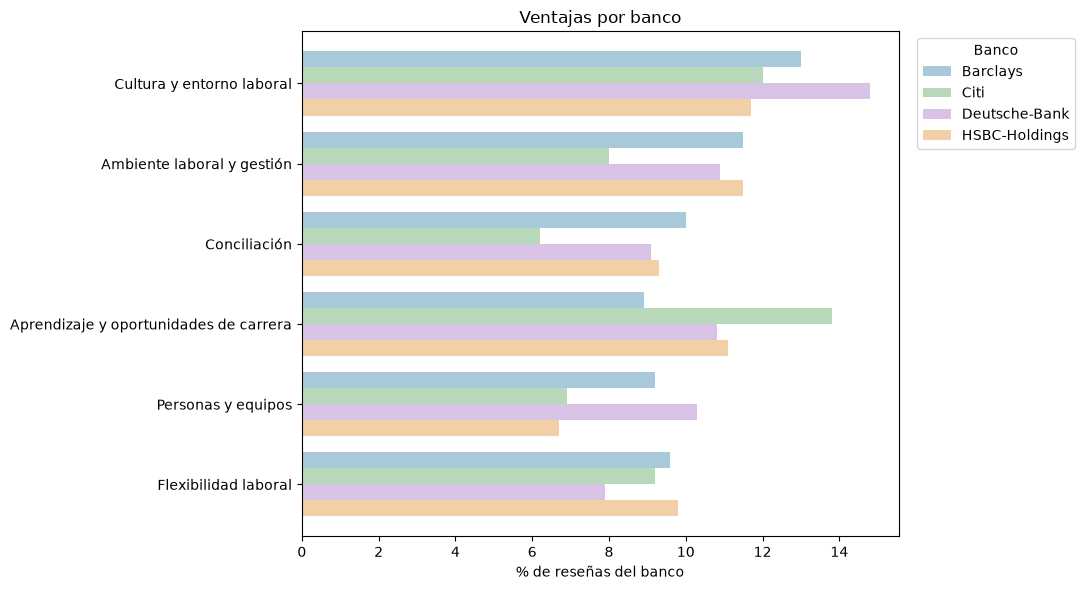

In [368]:
temas_grafico = ["Cultura y entorno laboral", "Ambiente laboral y gestión", "Conciliación", "Aprendizaje y oportunidades de carrera", "Personas y equipos", "Flexibilidad laboral",]

# Seleccionamos esos temas y giramos la tabla: los temas serán las filas y cada banco tendrá una barra.
datos_grafico = porcentajes_pros[temas_grafico].T
colores = ["#A8C9D9", "#B8D8BA", "#D8C3E6", "#F2D0A7"]

ax = datos_grafico.plot(
    kind="barh",
    figsize=(11, 6),
    width=0.8,
    color=colores)

ax.set_title("Ventajas por banco")
ax.set_xlabel("% de reseñas del banco")
ax.set_ylabel("")
ax.legend(title="Banco", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

En esta muestra de 1.000 reseñas positivas de Deutsche Bank, el grupo más frecuente del modelo es «Cultura y entorno laboral» (14,8 %). También destacan «Ambiente laboral y gestión» (10,9 %), «Conciliación» (9,1 %) «Aprendizaje y oportunidades de carrera» (10,8 %) y «Personas y equipos» (10,3 %). En comparación con el resto de bancos, Deutsche Bank presenta la mayor proporción de reseñas asignadas al grupo de cultura y la menor en el de flexibilidad.

### ¿Qué temas aparecen con más frecuencia en las reseñas negativas de Deutsche Bank frente a sus competidores?

Ahora realizaremos los mismos pasos para los comentarios de la columna "cons".

In [369]:
# Conservamos las reseñas originales en df_nlp["cons"].
documentos_cons = df_nlp["cons"].tolist()

# Preparamos una copia del texto sin los nombres de los bancos, tal y como hicimos en pros.
documentos_cons_sin_bancos = [
    patron_bancos.sub("", comentario).strip()
    for comentario in documentos_cons]

print("Comentarios de cons preparados:", len(documentos_cons_sin_bancos))

Comentarios de cons preparados: 4000


In [370]:
# Ahora entrenamos el modelo de cons usando la misma configuración que para pros.
modelo_cons = BERTopic(
    embedding_model="all-MiniLM-L6-v2",
    umap_model=reduccion_umap,
    hdbscan_model=KMeans(
        n_clusters=12,
        random_state=42,
        n_init=10),
    vectorizer_model=CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2)),
    calculate_probabilities=False,
    verbose=True)

temas_cons, _ = modelo_cons.fit_transform(documentos_cons_sin_bancos)

display(modelo_cons.get_topic_info()[["Topic", "Count", "Name"]])

2026-10-14 16:41:14,249 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-14 16:41:54,704 - BERTopic - Embedding - Completed ✓
2026-10-14 16:41:54,707 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 16:42:49,606 - BERTopic - Dimensionality - Completed ✓
2026-10-14 16:42:49,610 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 16:42:49,735 - BERTopic - Cluster - Completed ✓
2026-10-14 16:42:49,742 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 16:42:50,123 - BERTopic - Representation - Completed ✓


,Topic,Count,Name
0,0,646,0_hours_work_long_life
1,1,591,1_management_managers_senior_employees
2,2,443,2_salary_bonus_pay_low
3,3,331,3_technology_slow_systems_processes
4,4,326,4_growth_career_progression_slow
5,5,317,5_bureaucracy_bureaucratic_big_large
6,6,276,6_cons_cons cons_good_company
7,7,272,7_think_good_far_mention
8,8,236,8_culture_politics_team_teams
9,9,215,9_training_location_work_job


In [371]:
# Quitamos palabras poco útiles para describir los inconvenientes.
patron_genericas_cons = re.compile(
    r"\b(?:bank|banks|company|cons)\b",
    flags=re.IGNORECASE
)

# Nueva copia para la segunda prueba; no cambiamos df_nlp ni el modelo anterior.
documentos_cons_v2 = [
    patron_genericas_cons.sub("", comentario).strip()
    for comentario in documentos_cons_sin_bancos
]

cambiados = sum(
    antes != despues
    for antes, despues in zip(documentos_cons_sin_bancos, documentos_cons_v2))

print(f"Comentarios modificados: {cambiados} de {len(documentos_cons_v2)}")

Comentarios modificados: 486 de 4000


In [372]:
# Segunda prueba: entrenamos con los textos sin palabras genéricas del sector.
modelo_cons_v2 = BERTopic(
    embedding_model="all-MiniLM-L6-v2",
    umap_model=reduccion_umap,
    hdbscan_model=KMeans(
        n_clusters=12,
        random_state=42,
        n_init=10),
    vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2)),
    calculate_probabilities=False,
    verbose=True)

temas_cons_v2, _ = modelo_cons_v2.fit_transform(documentos_cons_v2)

display(modelo_cons_v2.get_topic_info()[["Topic", "Count", "Name"]])

2026-10-14 16:42:50,855 - BERTopic - Embedding - Transforming documents to embeddings.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-14 16:43:31,855 - BERTopic - Embedding - Completed ✓
2026-10-14 16:43:31,857 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 16:44:25,140 - BERTopic - Dimensionality - Completed ✓
2026-10-14 16:44:25,143 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 16:44:25,282 - BERTopic - Cluster - Completed ✓
2026-10-14 16:44:25,292 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 16:44:25,744 - BERTopic - Representation - Completed ✓


,Topic,Count,Name
0,0,628,0_management_politics_culture_team
1,1,542,1_hours_long_work_working
2,2,488,2_salary_bonus_pay_low
3,3,420,3_think_good_far_say
4,4,350,4_bureaucracy_bureaucratic_large_big
5,5,340,5_technology_slow_systems_processes
6,6,340,6_employees_cost_people_management
7,7,233,7_growth_career_progression_slow
8,8,224,8_training_location_job_work
9,9,189,9_promotion_promoted_promotions_salary


In [373]:
# Asociamos las reseñas originales con los grupos del modelo nuevo.
revision_cons_v2 = df_nlp[["firm", "cons"]].copy()
revision_cons_v2["tema"] = temas_cons_v2

# Revisamos los grupos
for tema in [0, 1, 2]:
    print(f"\nTEMA {tema}")
    muestra = revision_cons_v2[
        revision_cons_v2["tema"] == tema
    ].sample(n=4, random_state=42)
    for comentario in muestra["cons"]:
        print("-", comentario[:350])


TEMA 0
- Managers can be very robotic and not empathatetic to a employees.
- Managers who are out of their depth
- Complex organization structures, in local, off shore teams.
- May lack attention due to the vast attendees in departments

TEMA 1
- Protected weekend is not so strictly observed
- Hours are bad sometimes and bonus ....
- Sometimes need to ot at night
- Bad working hours and lots of politics

TEMA 2
- less hikes and promotions less
- Annual bonus are getting less what it used to be.
- Below market salary particularly for transaction focussed roles. Leads to a vein drain.
- Medical benefit is below industry average


In [374]:
for tema in [3, 4, 5]:
    print(f"\nTEMA {tema}")
    muestra = revision_cons_v2[
        revision_cons_v2["tema"] == tema
    ].sample(n=4, random_state=42)
    for comentario in muestra["cons"]:
        print("-", comentario[:350])


TEMA 3
- I honestly cannot think of any cons.
- I don't feel like there is something to mention
- nothing bad at all, nothing bad
- As of now, no cons

TEMA 4
- Sometimes too much bureaucracy to define and execute initiatives
- How Simple Became Complicated - painfully bureaucratic
- Complex structure with numerous global stakeholders
- the investment banking culture sometimes

TEMA 5
- Can't improve too much on the tech skill
- Sometimes busy
Processes are sometimes complex
- Lack of actual progress on transformation.
- It is generally not inefficient in SME and retail bank. This is similar across the industry.


In [375]:
for tema in [6, 7, 8]:
    print(f"\nTEMA {tema}")
    muestra = revision_cons_v2[
        revision_cons_v2["tema"] == tema
    ].sample(n=4, random_state=42)
    for comentario in muestra["cons"]:
        print("-", comentario[:350])


TEMA 6
- Poor internal recruitment
Parachute managers (I’ve had 9… mostly rubbish)
Who you know rather than value you give
Poor training and career support
Poor monitoring of leaders
Some teams are aggressive and penny pinching - pot luck which.
- Forced reorganizations are inevitable.
No overtime pay.
- NO GROWTH, NO SALARY , IT guys used to get much higher pay but no the guy in operations. They need to assess the employees.
- Haphazard hiring for new employees

TEMA 7
- Very slow career progression, salary growth Work environment depends heavily on which team you’re assigned to
- Primary focus is international and not domestic,
- Not much career progression with HSBC.
- Not much room for progression in some areas of the business.

TEMA 8
- No organisation in training. Unattentive and unprofessional.
- Fast paced culture and everyone is fighting to shine
- Large company so it is sometimes hard to get exposure. People are spread out nationally and globally. The Chicago office is not l

In [376]:
for tema in [9, 10, 11]:
    print(f"\nTEMA {tema}")
    muestra = revision_cons_v2[
        revision_cons_v2["tema"] == tema
    ].sample(n=4, random_state=42)
    for comentario in muestra["cons"]:
        print("-", comentario[:350])


TEMA 9
- Slow
no promotional available
not good salary
- slow salary growth and a liitle limitation for market
- Not a top tier bank
- Old style of working and very male dominated

TEMA 10
- Technology, work life balance, capacity constraints
- Bureaucracy and Management, work life imbalance, unrealistic targets
- No complaints about worklife or management
- No Work-Life Balance and no overtime pay in technology departments

TEMA 11
- No Major concerns. good organization.
- Good environment and work place
- awful food to eat at work
- This company does provide good feed back


In [377]:
# Etiquetas manuales tras revisar ejemplos originales de cada tema de cons.
etiquetas_cons = {
    0: "Gestión y estructura organizativa",
    1: "Horarios y horas extra",
    2: "Salario y beneficios",
    3: "Sin inconvenientes",
    4: "Burocracia y complejidad",
    5: "Tecnología y transformación",
    6: "Gestión de personal y contratación",
    7: "Progresión profesional",
    8: "Cultura y organización del trabajo",
    9: "Progresión y condiciones laborales",
    10: "Conciliación y carga de trabajo",
    11: "Sin problema común identificable",}

In [378]:
# Contamos cuántas reseñas de cada banco asignó el modelo v2 a cada tema.
tabla_temas_cons = pd.crosstab(
    revision_cons_v2["firm"],
    revision_cons_v2["tema"])

# Sustituimos los números de los temas por las etiquetas revisadas.
tabla_cons_etiquetada = tabla_temas_cons.rename(columns=etiquetas_cons)

# Calculamos el porcentaje sobre las reseñas de cada banco.
porcentajes_cons = (tabla_cons_etiquetada
    .div(tabla_cons_etiquetada.sum(axis=1), axis=0)
    .mul(100)
    .round(1))

display(porcentajes_cons)

tema,Gestión y estructura organizativa,Horarios y horas extra,Salario y beneficios,Sin inconvenientes,Burocracia y complejidad,Tecnología y transformación,Gestión de personal y contratación,Progresión profesional,Cultura y organización del trabajo,Progresión y condiciones laborales,Conciliación y carga de trabajo,Sin problema común identificable
firm,,,,,,,,,,,,
Barclays,17.9,12.5,7.8,14.4,8.3,9.3,6.5,6.3,6.2,4.4,4.3,2.1
Citi,15.7,17.7,10.0,9.2,9.0,7.6,8.2,5.1,5.8,4.3,6.3,1.1
Deutsche-Bank,15.0,12.0,17.1,8.8,7.1,9.0,10.4,4.4,4.2,6.0,3.2,2.8
HSBC-Holdings,14.2,12.0,13.9,9.6,10.6,8.1,8.9,7.5,6.2,4.2,2.6,2.2


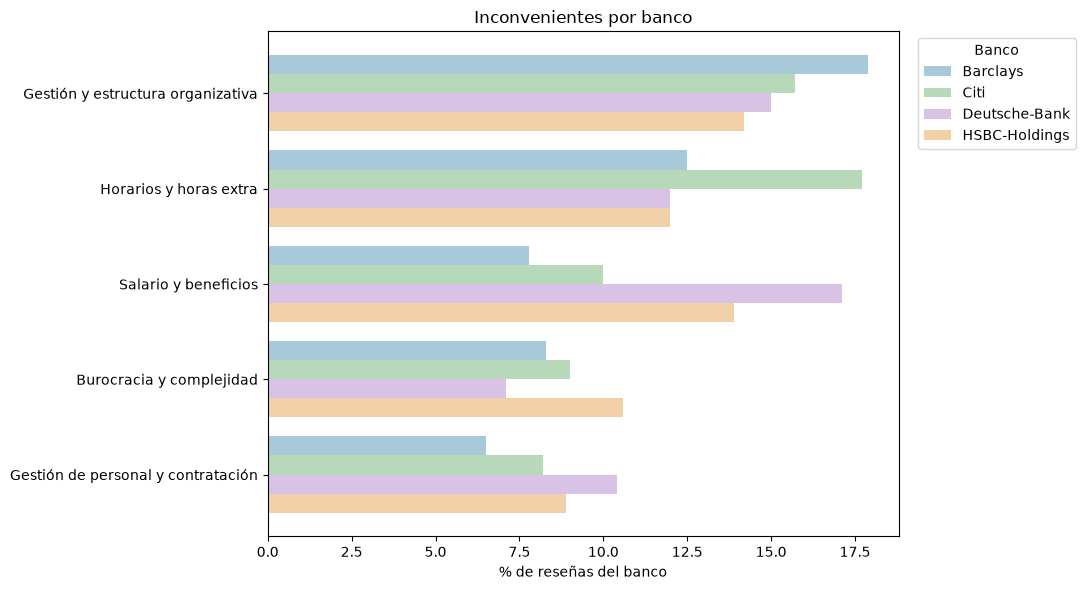

In [379]:
temas_grafico_cons = [
    "Gestión y estructura organizativa",
    "Horarios y horas extra",
    "Salario y beneficios",
    "Burocracia y complejidad",
    "Gestión de personal y contratación"]

# Giramos la tabla para poner los temas en el eje vertical.
datos_grafico_cons = porcentajes_cons[temas_grafico_cons].T


ax = datos_grafico_cons.plot(
    kind="barh",
    figsize=(11, 6),
    width=0.8,
    color=colores)

ax.set_title("Inconvenientes por banco")
ax.set_xlabel("% de reseñas del banco")
ax.set_ylabel("")
ax.legend(title="Banco", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

En la muestra de 1.000 reseñas por banco, «Salario y beneficios» es el grupo de inconvenientes más frecuente de Deutsche Bank (17,1 %) y presenta una proporción mayor que en los tres bancos comparados. También aparecen con frecuencia comentarios asignados a gestión y estructura organizativa (15,0 %) y horarios y horas extra (12,0 %). Los porcentajes describen los grupos asignados por el modelo; cada comentario puede contener varios problemas y algunos grupos reúnen asuntos distintos. «Sin inconvenientes» y «Sin problema común identificable» se muestran en la tabla, pero no se interpretan como tipos de queja.

In [380]:
# Agrupamos los temas de pros y cons en las mismas categorías de negocio para poder compararlos.
# Los temas genéricos ("Sin inconvenientes", "Valoración general"...) no se asignan a ninguna categoría y quedan fuera.
categorias_pros = {
    "Salario y compensación": "Compensación",
    "Beneficios y compensación": "Compensación",
    "Flexibilidad laboral": "Conciliación y horarios",
    "Conciliación": "Conciliación y horarios",
    "Aprendizaje y oportunidades de carrera": "Carrera y aprendizaje",
    "Cultura y entorno laboral": "Cultura y personas",
    "Personas y equipos": "Cultura y personas",
    "Ambiente laboral y gestión": "Cultura y personas"}

categorias_cons = {
    "Salario y beneficios": "Compensación",
    "Horarios y horas extra": "Conciliación y horarios",
    "Conciliación y carga de trabajo": "Conciliación y horarios",
    "Progresión profesional": "Carrera y aprendizaje",
    "Progresión y condiciones laborales": "Carrera y aprendizaje",
    "Cultura y organización del trabajo": "Cultura y personas",
    "Gestión y estructura organizativa": "Dirección y gestión",
    "Gestión de personal y contratación": "Dirección y gestión",
    "Burocracia y complejidad": "Procesos y herramientas",
    "Tecnología y transformación": "Procesos y herramientas"}

def agrupar_en_categorias(porcentajes, correspondencia):
    # Nos quedamos con los temas asignados y sumamos los que pertenecen a la misma categoría.
    return porcentajes[list(correspondencia)].T.groupby(correspondencia).sum().T

pros_categorias = agrupar_en_categorias(porcentajes_pros, categorias_pros)
cons_categorias = agrupar_en_categorias(porcentajes_cons, categorias_cons)

print("% de reseñas de pros por categoría:")
display(pros_categorias.round(1))
print("\n% de reseñas de cons por categoría:")
display(cons_categorias.round(1))

# Porcentaje de reseñas que queda fuera por pertenecer a temas genéricos.
print("\n% de reseñas sin categoría (pros):")
print((100 - pros_categorias.sum(axis=1)).round(1).to_string())
print("\n% de reseñas sin categoría (cons):")
print((100 - cons_categorias.sum(axis=1)).round(1).to_string())

% de reseñas de pros por categoría:


tema,Carrera y aprendizaje,Compensación,Conciliación y horarios,Cultura y personas
firm,,,,
Barclays,8.9,17.7,19.6,33.7
Citi,13.8,24.8,15.4,26.9
Deutsche-Bank,10.8,17.6,17.0,36.0
HSBC-Holdings,11.1,18.3,19.1,29.9



% de reseñas de cons por categoría:


tema,Carrera y aprendizaje,Compensación,Conciliación y horarios,Cultura y personas,Dirección y gestión,Procesos y herramientas
firm,,,,,,
Barclays,10.7,7.8,16.8,6.2,24.4,17.6
Citi,9.4,10.0,24.0,5.8,23.9,16.6
Deutsche-Bank,10.4,17.1,15.2,4.2,25.4,16.1
HSBC-Holdings,11.7,13.9,14.6,6.2,23.1,18.7



% de reseñas sin categoría (pros):
firm
Barclays         20.1
Citi             19.1
Deutsche-Bank    18.6
HSBC-Holdings    21.6

% de reseñas sin categoría (cons):
firm
Barclays         16.5
Citi             10.3
Deutsche-Bank    11.6
HSBC-Holdings    11.8


In [381]:
# Balance neto por categoría (% en pros - % en cons) y gap de Deutsche Bank frente a la media de los peers.
# Solo se puede calcular en las categorías que aparecen en pros y en cons.
categorias_comunes = pros_categorias.columns.intersection(cons_categorias.columns)
balance_categorias = pros_categorias[categorias_comunes] - cons_categorias[categorias_comunes]

comparacion_balance = pd.DataFrame({
    "Deutsche Bank": balance_categorias.loc[empresa],
    "Media peers": balance_categorias.loc[competidoras].mean()})

# Gap negativo = Deutsche Bank está peor que la media de sus competidores.
comparacion_balance["Gap (pp)"] = comparacion_balance["Deutsche Bank"] - comparacion_balance["Media peers"]

print("Balance neto por banco (puntos porcentuales):")
display(balance_categorias.round(1))
print("Balance neto de Deutsche Bank frente a la media de los peers:")
display(comparacion_balance.sort_values("Gap (pp)").round(1))

# Categorías que solo aparecen como inconveniente: no hay balance, comparamos su peso en los cons.
categorias_solo_cons = cons_categorias.columns.difference(categorias_comunes)

comparacion_solo_cons = pd.DataFrame({
    "Deutsche Bank": cons_categorias.loc[empresa, categorias_solo_cons],
    "Media peers": cons_categorias.loc[competidoras, categorias_solo_cons].mean()})

# Diferencia positiva = más quejas en Deutsche Bank que en los peers.
comparacion_solo_cons["Diferencia (pp)"] = comparacion_solo_cons["Deutsche Bank"] - comparacion_solo_cons["Media peers"]

print("Categorías solo de cons (% de reseñas):")
display(comparacion_solo_cons.round(1))

Balance neto por banco (puntos porcentuales):


tema,Carrera y aprendizaje,Compensación,Conciliación y horarios,Cultura y personas
firm,,,,
Barclays,-1.8,9.9,2.8,27.5
Citi,4.4,14.8,-8.6,21.1
Deutsche-Bank,0.4,0.5,1.8,31.8
HSBC-Holdings,-0.6,4.4,4.5,23.7


Balance neto de Deutsche Bank frente a la media de los peers:


,Deutsche Bank,Media peers,Gap (pp)
tema,,,
Compensación,0.5,9.7,-9.2
Carrera y aprendizaje,0.4,0.7,-0.3
Conciliación y horarios,1.8,-0.4,2.2
Cultura y personas,31.8,24.1,7.7


Categorías solo de cons (% de reseñas):


,Deutsche Bank,Media peers,Diferencia (pp)
tema,,,
Dirección y gestión,25.4,23.8,1.6
Procesos y herramientas,16.1,17.6,-1.5


,Peso en los cons (%),Desventaja vs peers (pp),Prioridad
tema,,,
Compensación,17.1,9.2,Prioritaria
Dirección y gestión,25.4,1.6,"Frecuente, en línea con los peers"
Carrera y aprendizaje,10.4,0.3,Baja prioridad
Procesos y herramientas,16.1,-1.5,"Frecuente, en línea con los peers"
Conciliación y horarios,15.2,-2.2,"Frecuente, en línea con los peers"
Cultura y personas,4.2,-7.7,Baja prioridad


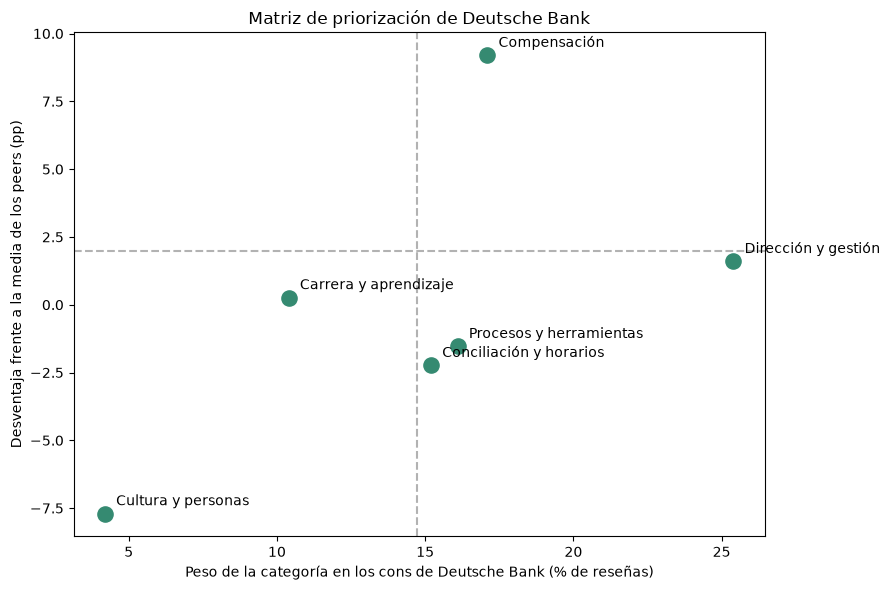

In [382]:
# Matriz de priorización
# Desventaja positiva = Deutsche Bank está peor que la media de los peers (se invierte el signo del gap del balance).
matriz = pd.DataFrame({
    "Peso en los cons (%)": cons_categorias.loc[empresa],
    "Desventaja vs peers (pp)": pd.concat([-comparacion_balance["Gap (pp)"], comparacion_solo_cons["Diferencia (pp)"]])})

# Con 1.000 reseñas por banco, diferencias de 1-2 puntos pueden deberse al azar de la muestra: exigimos 2 pp para hablar de desventaja real.
umbral_desventaja = 2
umbral_peso = matriz["Peso en los cons (%)"].mean()

def clasificar(fila):
    muy_frecuente = fila["Peso en los cons (%)"] >= umbral_peso
    en_desventaja = fila["Desventaja vs peers (pp)"] >= umbral_desventaja
    if muy_frecuente and en_desventaja:
        return "Prioritaria"
    if en_desventaja:
        return "Vigilar"
    if muy_frecuente:
        return "Frecuente, en línea con los peers"
    return "Baja prioridad"

matriz["Prioridad"] = matriz.apply(clasificar, axis=1)
display(matriz.sort_values("Desventaja vs peers (pp)", ascending=False).round(1))

# Gráfico: arriba a la derecha están las categorías más frecuentes y con más desventaja.
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(matriz["Peso en los cons (%)"], matriz["Desventaja vs peers (pp)"], s=120, color="#358A71")

for categoria, fila in matriz.iterrows():
    ax.annotate(categoria, (fila["Peso en los cons (%)"], fila["Desventaja vs peers (pp)"]), textcoords="offset points", xytext=(8, 6))

ax.axhline(umbral_desventaja, color="grey", linestyle="--", alpha=0.6)
ax.axvline(umbral_peso, color="grey", linestyle="--", alpha=0.6)
ax.set_title("Matriz de priorización de Deutsche Bank")
ax.set_xlabel("Peso de la categoría en los cons de Deutsche Bank (% de reseñas)")
ax.set_ylabel("Desventaja frente a la media de los peers (pp)")

plt.tight_layout()
plt.show()

La matriz de priorización muestra que Compensación es la única categoría prioritaria: pesa un 17,1 % de los cons de Deutsche Bank y está 9,2pp por encima de la media de los peers. 

Dirección y gestión es la queja más frecuente (25,4 %), pero su peso es casi igual al de los competidores (23,8 %, solamente un 1,6pp por encima de la media de los peers), por lo que no podemos afirmar que se trate de una desventaja concreta de Dutsche Bank y no de una queja común en el sector.

In [383]:
# Contrastamos cada categoría de cons con el rating y la recomendación de las reseñas que se quejan de ella.
# Comprobamos que las tablas están alineadas antes de añadir columnas de df_nlp.
assert (revision_cons_v2["cons"].reset_index(drop=True).equals(df_nlp["cons"].reset_index(drop=True))), "Las filas de revision_cons_v2 y df_nlp no están alineadas"

cons_rating = revision_cons_v2[["firm"]].copy()
cons_rating["categoria"] = revision_cons_v2["tema"].map(etiquetas_cons).map(categorias_cons).fillna("Sin categoría")
cons_rating["overall_rating"] = df_nlp["overall_rating"].to_numpy()
cons_rating["recomienda_%"] = df_nlp["recommend"].eq("v").mul(100).to_numpy()

def resumen_por_categoria(datos):
    return datos.groupby("categoria").agg(
        reseñas=("overall_rating", "size"),
        rating_medio=("overall_rating", "mean"),
        recomienda_pct=("recomienda_%", "mean"))

# Deutsche Bank y, como contraste con más reseñas, los cuatro bancos juntos.
tabla_rating = pd.concat({
    "Deutsche Bank": resumen_por_categoria(cons_rating[cons_rating["firm"] == empresa]),
    "Los cuatro bancos": resumen_por_categoria(cons_rating)}, axis=1)

display(tabla_rating.sort_values(("Deutsche Bank", "rating_medio")).round(2))

# Referencia: media de todas las reseñas de la muestra de cada grupo.
print("Rating medio de la muestra de Deutsche Bank:", round(cons_rating.loc[cons_rating["firm"] == empresa, "overall_rating"].mean(), 2))
print("Rating medio de la muestra de los cuatro bancos:", round(cons_rating["overall_rating"].mean(), 2))

Deutsche Bank                              \
                              reseñas rating_medio recomienda_pct   
categoria                                                           
Dirección y gestión               254         3.21          34.25   
Carrera y aprendizaje             104         3.62          42.31   
Conciliación y horarios           152         3.64          36.84   
Cultura y personas                 42         3.76          33.33   
Procesos y herramientas           161         3.78          46.58   
Compensación                      171         3.80          47.37   
Sin categoría                     116         4.51          53.45   

                        Los cuatro bancos                              
                                  reseñas rating_medio recomienda_pct  
categoria                                                              
Dirección y gestión                   968         3.29          36.78  
Carrera y aprendizaje                 422         3.67          44.79  
Conciliación y horarios               706         3.77          41.93  
Cultura y personas                    224         3.76          46.43  
Procesos y herramientas               690         3.91          52.32  
Compensación                          488         3.78          51.02  
Sin categoría                         502         4.51          51.20

Rating medio de la muestra de Deutsche Bank: 3.68
Rating medio de la muestra de los cuatro bancos: 3.76


Al cruzar las categorías de quejas con el rating y la recomendación, **Dirección y gestión** es la que se asocia a peor valoración: las reseñas de Deutsche Bank que se quejan de ella puntúan 3,21 (frente a una media de 3,68 en la muestra) y solo el 34,3 % recomienda la empresa. Pasa lo mismo en los cuatro bancos (3,29), así que es un problema del sector.

**Compensación**, en cambio, no se asocia a peor valoración (3,80 y 47,4 % de recomendación). Es una debilidad relativa frente a los peers, pero no el motivo principal del descontento por que las reseñas que se quejan de la compensación no valoran tan mal el rating. 

Cultura y personas solo tiene 42 reseñas, así que su resultado es poco fiable.

Sobre los balances netos: en conciliación y horarios Deutsche Bank queda 2,2 puntos por encima de la media de los peers, pero esa media está muy influida por el resultado negativo de Citi (−8,6), por lo que no lo presentaríamos como una fortaleza clara.

### ¿Qué diferencia hay entre las reseñas de los empleados antiguos y actuales de Deustche Bank?

In [384]:
# Añadimos la situación laboral (ya calculada al inicio) respetando el orden de df_nlp.
revision_cons_v2["situacion"] = df_nlp["situacion"].to_numpy()

# Nos centramos en la empresa del proyecto.
cons_deutsche = revision_cons_v2[
    revision_cons_v2["firm"] == "Deutsche-Bank"].copy()

display(cons_deutsche["situacion"].value_counts())

situacion
Actual     624
Antiguo    376
Name: count, dtype: int64

In [385]:
# Calculamos el porcentaje de cada tema dentro de cada situación laboral.
comparacion_situacion_cons = pd.crosstab(
    cons_deutsche["situacion"],
    cons_deutsche["tema"],
    normalize="index"
).mul(100)

# Ponemos los temas en filas y sustituimos sus números por etiquetas.
comparacion_situacion_cons = (
    comparacion_situacion_cons
    .rename(columns=etiquetas_cons)
    .T)

# Diferencia en puntos porcentuales: positiva = más frecuente en actuales.
comparacion_situacion_cons["Diferencia (Actual - Antiguo)"] = (
    comparacion_situacion_cons["Actual"]
    - comparacion_situacion_cons["Antiguo"])

display(comparacion_situacion_cons.round(1))

situacion,Actual,Antiguo,Diferencia (Actual - Antiguo)
tema,,,
Gestión y estructura organizativa,13.6,17.3,-3.7
Horarios y horas extra,11.1,13.6,-2.5
Salario y beneficios,19.4,13.3,6.1
Sin inconvenientes,9.3,8.0,1.3
Burocracia y complejidad,8.3,5.1,3.3
Tecnología y transformación,9.8,7.7,2.1
Gestión de personal y contratación,8.5,13.6,-5.1
Progresión profesional,4.6,4.0,0.7
Cultura y organización del trabajo,3.2,5.9,-2.6


En la muestra de Deutsche Bank, las reseñas de empleados actuales se asignan con más frecuencia al grupo «Salario y beneficios» que las de antiguos empleados (19,4 % frente a 13,3 %). Entre los antiguos tienen mayor peso los grupos de gestión y estructura organizativa (17,3 % frente a 13,6 %) y gestión de personal y contratación (13,6 % frente a 8,5 %). Estas son diferencias descriptivas entre grupos de 624 y 376 reseñas; no demuestran que la situación laboral sea la causa de las diferencias.

In [386]:
# Añadimos la situación laboral a las reseñas de pros, igual que en cons.
revision_pros_sin_bancos["situacion"] = df_nlp["situacion"].to_numpy()

pros_deutsche = revision_pros_sin_bancos[revision_pros_sin_bancos["firm"] == "Deutsche-Bank"].copy()

# Porcentaje de cada tema dentro de actuales y dentro de antiguos.
comparacion_situacion_pros = pd.crosstab(
    pros_deutsche["situacion"],
    pros_deutsche["tema"],
    normalize="index").mul(100)

comparacion_situacion_pros = (comparacion_situacion_pros.rename(columns=etiquetas_pros).T)

comparacion_situacion_pros["Diferencia (Actual - Antiguo)"] = (comparacion_situacion_pros["Actual"] - comparacion_situacion_pros["Antiguo"])

display(comparacion_situacion_pros.round(1))

situacion,Actual,Antiguo,Diferencia (Actual - Antiguo)
tema,,,
Cultura y entorno laboral,14.1,16.0,-1.9
Aprendizaje y oportunidades de carrera,11.5,9.6,2.0
Salario y compensación,8.8,11.2,-2.4
Ambiente laboral y gestión,10.7,11.2,-0.4
Flexibilidad laboral,8.5,6.9,1.6
Beneficios y compensación,8.8,6.4,2.4
Conciliación,10.7,6.4,4.4
Personas y equipos,9.9,10.9,-1.0
Valoración general del lugar de trabajo,5.9,6.6,-0.7


Al comparar las ventajas mencionadas en las reseñas de Deutsche Bank, el grupo «Conciliación» tiene mayor peso entre empleados actuales (10,7 %) que entre antiguos (6,4 %). Entre los antiguos destaca algo más «Cultura y entorno laboral» (16,0 % frente a 14,1 %). 

Las diferencias describen asignaciones de temas en muestras de 624 y 376 reseñas, respectivamente; no miden directamente la satisfacción con cada aspecto

In [387]:
# Motivos de salida: cons de los antiguos empleados de Deutsche Bank frente a los de los peers.
# Reutilizamos la categoría de cada reseña calculada en la celda anterior (cons_rating).
cons_rating["situacion"] = df_nlp["situacion"].to_numpy()
cons_antiguos = cons_rating[cons_rating["situacion"] == "Antiguo"]

print("Reseñas de antiguos empleados por banco:")
print(cons_antiguos["firm"].value_counts().to_string())

# % de cada categoría dentro de los antiguos de cada banco (las reseñas sin categoría cuentan en el total pero no se muestran).
porcentajes_antiguos = pd.crosstab(cons_antiguos["firm"], cons_antiguos["categoria"], normalize="index").mul(100)
porcentajes_antiguos = porcentajes_antiguos.drop(columns="Sin categoría")

print()
print("% de cons por categoría entre los antiguos empleados de cada banco:")
display(porcentajes_antiguos.round(1))

comparacion_salida = pd.DataFrame({
    "Deutsche Bank": porcentajes_antiguos.loc[empresa],
    "Media peers": porcentajes_antiguos.loc[competidoras].mean()})

# Diferencia positiva = ese motivo pesa más entre los antiguos de Deutsche Bank que entre los de los peers.
comparacion_salida["Diferencia (pp)"] = comparacion_salida["Deutsche Bank"] - comparacion_salida["Media peers"]

print("Deutsche Bank frente a la media de los peers (antiguos empleados):")
display(comparacion_salida.sort_values("Diferencia (pp)", ascending=False).round(1))

Reseñas de antiguos empleados por banco:
firm
HSBC-Holdings    410
Deutsche-Bank    376
Citi             364
Barclays         327

% de cons por categoría entre los antiguos empleados de cada banco:


categoria,Carrera y aprendizaje,Compensación,Conciliación y horarios,Cultura y personas,Dirección y gestión,Procesos y herramientas
firm,,,,,,
Barclays,11.6,5.8,13.5,7.0,29.4,17.4
Citi,9.3,8.0,26.6,6.3,27.7,14.8
Deutsche-Bank,8.8,13.3,17.6,5.9,30.9,12.8
HSBC-Holdings,13.2,12.7,15.1,6.6,24.9,16.6


Deutsche Bank frente a la media de los peers (antiguos empleados):


,Deutsche Bank,Media peers,Diferencia (pp)
categoria,,,
Compensación,13.3,8.8,4.5
Dirección y gestión,30.9,27.3,3.5
Cultura y personas,5.9,6.6,-0.8
Conciliación y horarios,17.6,18.4,-0.9
Carrera y aprendizaje,8.8,11.4,-2.6
Procesos y herramientas,12.8,16.3,-3.5


Entre los antiguos empleados,  

- **Compensación** es donde Deutsche Bank más se separa de los peers: pesa un 13,3 % de sus cons frente a un 8,8 % de media (+4,5 pp). 
- **Dirección y gestión** es la queja más frecuente en los cuatro bancos (entre el 24,9 % y el 30,9 %). En Deutsche Bank es algo mayor (30,9 % frente a 27,3 %, +3,5 pp), pero con unas 330-410 reseñas de antiguos por banco esa diferencia es pequeña. 
- En cambio, Procesos y herramientas (−3,5 puntos) y Carrera y aprendizaje (−2,6) pesan menos que en los peers.

Esto no contradice el análisis anterior, donde dentro de Deutsche Bank los empleados actuales mencionaban más el salario que los antiguos (19,4 % frente a 13,3 %): aquí comparamos a los antiguos de Deutsche Bank con los antiguos de los peers, en cambio, esto podría estar detrás de algunas salidas, y convendría confirmarlo con entrevistas de salida reales.

## Recomendaciones

- **Compensación.** Es la única categoría prioritaria en la matriz: pesa un 17,1 % de los cons de Deutsche Bank (frente a un 7,8–13,9 % en los peers), su balance neto está 9,2 puntos por debajo de la media y entre los antiguos aparece más que en los peers (13,3 % frente a 8,8 %). Recomendamos comparar los paquetes de salario y beneficios con el mercado bancario. Pero las reseñas que se quejan de compensación no puntúan peor (3,80 frente a 3,68 de media) ni recomiendan menos (47,4 %), así que es una debilidad frente al mercado más que la causa del descontento: conviene confirmarla con datos internos antes de invertir.
- **Dirección y gestión.** Es la queja más frecuente (25,4 %) y la que se asocia a peor valoración: quienes la mencionan puntúan 3,21 y solo el 34,3 % recomienda la empresa. Ocurre igual en los otros bancos (23,8 %), así que no es una desventaja propia de Deutsche Bank, aunque entre los antiguos pesa algo más (30,9 % frente a 27,3 %). Recomendamos incluirla en las entrevistas de salida y revisar el apoyo a los mandos intermedios.
- **Cultura como reclamo de marca.** «Cultura y personas» es la mayor ventaja de Deutsche Bank en las reseñas (36,0 %, la más alta de los cuatro bancos) y apenas aparece como queja (4,2 %). Recomendamos identificar qué prácticas valoran más los empleados y usarlas en los procesos de selección. La conciliación y los horarios no los presentaríamos como fortaleza: están 2,2 puntos por encima de la media de los peers, pero esa media la baja el mal resultado de Citi.


## Limitaciones del análisis

- **Representatividad.** Glassdoor recoge opiniones voluntarias: quien escribe puede ser quien está especialmente contento o descontento. Los porcentajes describen esta muestra de 1.000 reseñas por banco, no a toda la plantilla.

- **Mezcla de países y áreas.** El dataset junta reseñas de distintos países, puestos y áreas dentro de cada banco, y no podemos separarlas. Una queja de salario puede ser muy distinta en un puesto de oficina y en uno de banca de inversión, y las diferencias entre bancos pueden deberse a esa mezcla.

- **Periodo desigual entre bancos.** HSBC no tiene reseñas en 2022 y 2023, así que su rating y sus temas reflejan un periodo distinto al del resto. La comparación con los otros tres bancos es menos exacta.

- **Un tema por comentario.** El modelo asigna un único tema a cada texto, aunque una persona pueda mencionar salario, gestión y horarios en el mismo comentario. Los porcentajes indican asignaciones del modelo, no todas las menciones reales de cada asunto.

- **Precisión de los topics.** KMeans distribuye todos los comentarios entre 12 grupos, incluso cuando alguno no encaja claramente. El número 12 fue una decisión de diseño (la justificamos al probar KMeans) y no la contrastamos con otros valores. Algunos grupos mezclan problemas distintos, y las etiquetas se asignaron tras leer unos pocos ejemplos de cada uno, no tras revisar todas las reseñas.

- **Agrupación en categorías.** Agrupamos los temas en categorías de negocio a mano, y algunas tienen más temas en pros que en cons (por eso el balance neto de «Cultura y personas» sale muy alto). Los umbrales de la matriz de priorización (2 puntos de desventaja y la media de los pesos) son decisiones nuestras. Además, «Cultura y personas» solo tiene 42 reseñas de cons de Deutsche Bank, así que su cruce con el rating es poco fiable.

- **Contenido de `cons`.** No todos los textos de esta columna son quejas: hay respuestas como «no tengo inconvenientes». Por eso el grupo «Sin inconvenientes» se muestra por separado y no se interpreta como un problema laboral.

- **Preprocesamiento.** Para evitar grupos formados alrededor de nombres de bancos y palabras genéricas se entrenó con copias modificadas de los comentarios. Esa limpieza puede eliminar contexto útil. Los textos originales se conservaron para revisar e interpretar los resultados.

- **Sentimiento.** DistilBERT cumple como control de calidad en conjunto (92–93 % de pros positivos y 80–85 % de cons negativos), pero falla en textos ambiguos, sarcásticos o neutros, a veces con una confianza alta. Por eso no usamos el sentimiento como evidencia principal de las recomendaciones.

- **Comparaciones descriptivas.** Las diferencias entre bancos o entre empleados actuales y antiguos no prueban causalidad. También pueden influir el puesto, el país, la fecha de la reseña y quién decide participar. Además, los antiguos puntúan más bajo en todos los bancos, por lo que solo comparamos sus temas y no sus puntuaciones.

## Próximos pasos

- **Mejorar los temas.** Probar otros valores de k (y comprobar si los grupos se mantienen), o volver a HDBSCAN reasignando después los comentarios sin tema al grupo más cercano. También separar los comentarios largos en frases para que cada una tenga su propio tema.
- **Validar las etiquetas.** Que una segunda persona revise la asignación de temas en una muestra para medir cuánto coincide con la nuestra.
- **Contrastar con datos internos.** Comparar estos temas con encuestas de clima, rotación y salarios reales de Deutsche Bank, para saber si Glassdoor refleja lo que ocurre dentro.
- **Afinar la comparación.** Analizar por país, área y antigüedad, y la evolución temporal de las categorías (por ejemplo, antes y después de 2020), con un periodo común para todos los bancos.
- **Sentimiento más fiable.** Probar un modelo ajustado con reseñas de empleo, o uno que distinga también el sentimiento neutro.

## Próximos pasos

- **Mejorar los temas.** Probar otros valores de k (y comprobar si los grupos se mantienen), o volver a HDBSCAN reasignando después los comentarios sin tema al grupo más cercano. También separar los comentarios largos en frases para que cada una tenga su propio tema.
- **Validar las etiquetas.** Que una segunda persona revise la asignación de temas en una muestra para medir cuánto coincide con la nuestra.
- **Contrastar con datos internos.** Comparar estos temas con encuestas de clima, rotación y salarios reales de Deutsche Bank, para saber si Glassdoor refleja lo que ocurre dentro.
- **Afinar la comparación.** Analizar por país, área y antigüedad, y la evolución temporal de las categorías (por ejemplo, antes y después de 2020), con un periodo común para todos los bancos.
- **Sentimiento más fiable.** Probar un modelo ajustado con reseñas de empleo, o uno que distinga también el sentimiento neutro.

## Conclusión

Deutsche Bank tiene un rating medio de 3,73/5 que ha subido de 3,40 en 2019 a 3,84 en 2022, aunque algo similar ocurre en los otros tres bancos. Es el banco con menos reseñas que recomiendan la empresa (43,4 % frente a 45,7–48,0 %).

**Fortalezas.** «Cultura y personas» es su mayor ventaja (36,0 % de las reseñas, la más alta de los cuatro bancos), casi no aparece como queja (4,2 %) y su balance neto es 7,7 puntos mejor que la media de los peers. En conciliación y horarios está 2,2 puntos por encima de la media, pero esa media baja por el mal resultado de Citi, por lo que no la presentaríamos como una fortaleza clara.

**Áreas de mejora.** La matriz de priorización señala «Compensación» como la única categoría prioritaria: pesa un 17,1 % de los cons y su balance neto está 9,2 puntos por debajo de los peers. Sin embargo, las reseñas que se quejan de ella no puntúan peor ni recomiendan menos, así que es una debilidad relativa más que la causa principal del descontento. Lo que sí se asocia a peor valoración es «Dirección y gestión» (rating 3,21 y 34,3 % de recomendación), pero es la queja más frecuente en los cuatro bancos y no una desventaja propia de Deutsche Bank.

**Actuales y antiguos.** Los antiguos, que son en la práctica motivos de salida, mencionan más «Compensación» que los antiguos de los peers (13,3 % frente a 8,8 %) y algo más «Dirección y gestión» (30,9 % frente a 27,3 %, una diferencia pequeña). Dentro de Deutsche Bank, los antiguos pesan más en gestión de personal y contratación (13,6 % frente a 8,5 % en actuales), y los actuales mencionan más el salario (19,4 % frente a 13,3 %).

Estos resultados sirven para orientar la investigación interna: contrastar la compensación con el mercado, preguntar por la gestión en las entrevistas de salida y aprovechar la cultura en los procesos de selección. Son señales obtenidas de reseñas voluntarias y de grupos asignados automáticamente, y deben contrastarse con datos internos antes de tomar decisiones.